# Preparación de imágenes de RM para MedSAM2

**Objetivo.** Dejar los 9 volúmenes de resonancia de la articulación sacroilíaca (STIR, coronal oblicuo) listos para MedSAM2 (Ma et al., 2025): guardados como `uint8` 0–255 con forma `(D, H, W)` = (cortes, 400, 400); MedSAM2 convierte internamente cada corte a 3×512×512. El notebook cubre todo el flujo: descarga, lectura y verificación de los archivos `.raw`, corrección del campo de sesgo (N4), recorte y normalización por volumen, la vista de lo que ve el modelo, el guardado en `data/processed/` y la sugerencia de un corte clave.

**Fuente de los datos.** Gut (2022), licencia CC BY 4.0. Los parámetros de adquisición vienen de Gut et al. (2024).

**Índice de pasos**
1. Parámetros y descarga (solo si faltan archivos).
2. Contexto del dataset: adquisición, sesgos y por qué solo sirve el plano adquirido.
3. Lectura de los 9 volúmenes y mosaico de `SIJ_1`.
4. Verificación del orden de los ejes (el notebook se detiene si falla).
5. Corrección del campo de sesgo (N4): máscara del cuerpo, parámetros y resultados.
6. Comparación de criterios de recorte y revisión de la saturación.
7. Normalización final por volumen a `uint8`.
8. Lo que ve el modelo: 3 canales, 512×512 y normalización de ImageNet.
9. Guardado de los volúmenes y del archivo de parámetros, con verificación.
10. Corte clave sugerido.
11. Resumen y pasos siguientes.

**Cómo ejecutar.**
1. Instalar [uv](https://docs.astral.sh/uv/) (gestor de entornos de Python).
2. Desde la raíz del repositorio: `uv sync`.
3. Abrir el notebook con `uv run jupyter lab`, o en VS Code seleccionando el kernel de `.venv`.
4. La primera celda de código descarga unos 58 MB la primera vez (las siguientes ejecuciones no descargan nada).

Si aparece `ModuleNotFoundError: sij_prep`, el kernel no es el `.venv` del proyecto.

**Advertencia: las salidas de este notebook contienen imágenes de RM de pacientes y nunca deben subirse al repositorio.** Ejecute una sola vez `uv run nbstripout --install`, que instala un filtro de git que borra las salidas al hacer *commit*. Alternativa: limpiar las salidas antes de cada *commit* (`Kernel → Restart & Clear Output`, o `uv run jupyter nbconvert --clear-output --inplace notebooks/01_preparacion_imagenes.ipynb`).

**Regla del proyecto.** Las imágenes nunca van al repositorio: se descargan a `data/raw/` y se procesan a `data/processed/`, ambas carpetas ignoradas por git.

## 1. Parámetros y descarga

**Qué se hace.** La celda siguiente importa lo necesario, fija todos los parámetros del flujo en un solo lugar y llama a `ensure_dataset`. Si los 9 archivos ya están en `data/raw/` con el `sha256` correcto, los marca como `presente` y no descarga nada; si falta alguno, lo baja de Mendeley (hasta 3 reintentos, escribiendo primero a un archivo `.part` y renombrando al final, así que una descarga interrumpida no deja un archivo corrupto).

**Por qué.** Que el notebook se pueda ejecutar desde cero en cualquier computador, y que nunca continúe con datos corruptos: la integridad se comprueba contra el `sha256` de cada archivo. Los nombres de archivo, las URL y los `sha256` se tomaron de la API pública de Mendeley (versión 1 del dataset) el 2026-11-10 y quedaron fijados en el código (`KNOWN_FILES`), así que la comprobación funciona sin conexión.

**Qué mirar.** La tabla debe mostrar 9 filas, todas con `sha256_ok = True`. La primera vez dirán `descargado`; las siguientes, `presente`.

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
from IPython.display import Markdown, display

from sij_prep.download import ensure_dataset
from sij_prep.io import (
    VOXEL_SPACING_XYZ_MM,
    axis_order_check,
    list_local_volumes,
    parse_raw_filename,
    read_raw,
    repo_root,
)
from sij_prep.viz import plot_central_slices, plot_mosaic, plot_orthogonal_check

# --- Parámetros (se usan en las secciones 5 a 9) ---
ROOT = repo_root(Path.cwd())
RAW_DIR = ROOT / "data/raw"
PROC_DIR = ROOT / "data/processed"
CLIP_LOW_PCT = 0.5       # percentil inferior del recorte de intensidad
CLIP_HIGH_PCT = 99.5     # percentil superior del recorte de intensidad
MASK_METHOD = "low_threshold"  # máscara cuerpo/fondo para N4
N4_SHRINK = 4            # factor de reducción para acelerar N4
N4_ITERS = (50, 50, 50)  # 3 niveles (no 4): así el campo de sesgo no sigue la anatomía

# --- Descarga (omite los archivos que ya están) ---
resultados = ensure_dataset(RAW_DIR)
filas = ["| Archivo | Estado | Tamaño (bytes) | sha256 correcto |", "|---|---|---:|:---:|"]
for r in resultados:
    filas.append(f"| `{r.filename}` | {r.status} | {r.size:,} | {r.sha256_ok} |")
display(Markdown("\n".join(filas)))

| Archivo | Estado | Tamaño (bytes) | sha256 correcto |
|---|---|---:|:---:|
| `SIJ_1_400_400_18_2_.raw` | presente | 5,760,000 | True |
| `SIJ_2_400_400_24_2_.raw` | presente | 7,680,000 | True |
| `SIJ_3_400_400_18_2_.raw` | presente | 5,760,000 | True |
| `SIJ_4_400_400_20_2_.raw` | presente | 6,400,000 | True |
| `SIJ_5_400_400_23_2_.raw` | presente | 7,360,000 | True |
| `SIJ_6_400_400_20_2_.raw` | presente | 6,400,000 | True |
| `SIJ_7_400_400_18_2_.raw` | presente | 5,760,000 | True |
| `SIJ_8_400_400_18_2_.raw` | presente | 5,760,000 | True |
| `SIJ_9_400_400_22_2_.raw` | presente | 7,040,000 | True |

## 2. Contexto del dataset

### 2.1 Adquisición (Gut et al., 2024, §2.1)

- Resonador de **3.0 T** (Philips Achieva) con bobina XL-torso de 8 canales.
- Solo la secuencia **STIR** turbo spin echo, con supresión de grasa: el edema y los fluidos se ven brillantes y la médula grasa se ve oscura.
- Plano **coronal oblicuo**, paralelo al eje largo del sacro, con ambas articulaciones sacroilíacas en el mismo corte, de anterior a posterior.
- TR 5239 ms, TE 30 ms, TI 190 ms, NEX 2.
- **Grosor de corte de 3 mm**, matriz de 400×400 y FOV de 240×240 mm, es decir, **0.6×0.6 mm en el plano**. El artículo no informa separación entre cortes.
- **9 pacientes** con sacroileítis en espondiloartritis axial; 18 a 24 cortes por volumen. Los nombres de archivo codifican la geometría: `tipo_paciente_ancho_alto_cortes_bytesPorPixel_.raw`.
- Formato `.raw`: enteros de 16 bits *big-endian*, sin encabezado; el tamaño de cada archivo es exactamente `400·400·cortes·2` bytes.

**Implicación de STIR para este proyecto.** El edema de la médula ósea se ve brillante y puede tomar los valores más altos del volumen. Por eso el recorte por percentiles de la sección 6 debe revisarse para **no saturar las lesiones**.

### 2.2 Sesgos del dataset y condiciones para imágenes nuevas

Las características anteriores definen el **dominio** en que se preparan las imágenes y en el que trabajarán las máscaras y la U-Net:

| Característica | Valor en el dataset | Sesgo que introduce | Condición para imágenes nuevas |
|---|---|---|---|
| Centro y escáner | Un solo centro; Philips Achieva de 3.0 T | El contraste, el ruido y la inhomogeneidad son los de un solo equipo | Con otro fabricante o con 1.5 T cambian el contraste y la relación señal/ruido. Esperar caída de desempeño (*domain shift*) |
| Secuencia | Solo STIR | El modelo aprende la apariencia de la articulación en STIR, donde la grasa se ve oscura y el edema brillante | No sirve directamente para T1, T2 con supresión SPAIR u otras secuencias |
| Plano | Coronal oblicuo, paralelo al sacro | La forma 2D de la articulación depende del plano | Las imágenes nuevas deben estar en coronal oblicuo; los cortes axiales u otras angulaciones son otro problema |
| Resolución | 0.6×0.6 mm en el plano y cortes de 3 mm | El tamaño aparente de las estructuras en píxeles es fijo | Si el FOV o la matriz cambian, hay que **remuestrear a 0.6 mm en el plano** antes de aplicar el modelo |
| Pacientes | 9, todos con sacroileítis por espondiloartritis axial | No hay sujetos sanos, y el edema y las erosiones alteran los bordes. Muestra muy pequeña | En articulaciones sanas, o con otras patologías, el comportamiento es desconocido |
| Cobertura | 18 a 24 cortes (54 a 72 mm), de anterior a posterior | La cobertura y la posición del primer corte varían entre pacientes | Hay que verificar que el volumen nuevo cubra la articulación completa |

**Para el artículo:** los resultados son válidos **en este dominio** (STIR coronal oblicuo, 3 T, sacroileítis activa). La validación con la cohorte de la FSFB medirá cuánto se degrada el modelo fuera de él.

### 2.3 ¿Por qué no hay otros planos útiles?

- Un volumen es una grilla de 400 × 400 × ~20 vóxeles de 0.6 × 0.6 × 3 mm.
- **Plano adquirido (coronal oblicuo):** cada corte tiene 400×400 píxeles de 0.6 mm y cubre 240 mm de lado. Es la máxima resolución disponible.
- **Plano reconstruido (axial o sagital):** se toma una fila de cada corte y se apilan. Resulta una imagen de **400 × ~20 píxeles**: a lo ancho siguen siendo píxeles de 0.6 mm, pero a lo alto solo ~20 píxeles de 3 mm (unos 60 mm). Para verla con proporciones reales hay que estirar cada píxel 5 veces en vertical y aparecen escalones. La interpolación los suaviza pero **no crea detalle** que no se midió: un borde que cambia dentro de esos 3 mm se pierde.
- Por eso **solo el plano adquirido sirve para anotar y segmentar**. Los otros planos sirven, como mucho, para verificar visualmente el orden de los cortes (paso 4).

## 3. Lectura de los 9 volúmenes

**Qué se hace.** `list_local_volumes` lista solo los `SIJ_*.raw` en orden numérico (ignora archivos ajenos como `.DS_Store`). `read_raw` lee cada uno como `uint16` big-endian (`>u2`) y lo reordena a `(D, H, W)` = (cortes, filas, columnas), con la geometría tomada del nombre del archivo. Luego se tabulan la forma, el mínimo, el máximo y los percentiles 0.5, 1, 50, 99 y 99.5 de cada volumen.

**Por qué.** La RM no tiene una escala de intensidad fija: el mismo tejido puede dar valores distintos entre exámenes (Nyúl & Udupa, 1999). Estos números son los que justifican normalizar **cada volumen por separado**. En estos datos se observa que el máximo por volumen va desde 557 (`SIJ_1`) hasta 2891 (`SIJ_7`), un factor de más de 5; es una observación de este dataset, no una regla general. Los percentiles 0.5 y 99.5 son los que usará el recorte de la sección 6. Ojo: los percentiles de esta tabla **incluyen el fondo** (los ceros fuera del cuerpo), mientras que el recorte de la sección 6 los calcula **dentro de la máscara del cuerpo**, así que sus valores serán distintos.

**Qué mirar.**
- En la tabla: que la forma coincida con el nombre del archivo y que el máximo y el p99.5 varíen mucho entre volúmenes. Si el p99.5 queda muy por debajo del máximo, hay unos pocos vóxeles muy brillantes.
- En el mosaico de `SIJ_1`: todos los cortes con la **misma escala de intensidad**, de anterior a posterior. Debe verse una pelvis en coronal oblicuo (sacro con forámenes, ambas articulaciones sacroilíacas e ilíacos), con la grasa oscura y los fluidos brillantes, como corresponde a STIR.

| Volumen | Forma (D,H,W) | Mín | Máx | p0.5 | p1 | p50 | p99 | p99.5 |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| `SIJ_1` | (18, 400, 400) | 0 | 557 | 0 | 0 | 104 | 258 | 282 |
| `SIJ_2` | (24, 400, 400) | 0 | 1636 | 0 | 0 | 250 | 759 | 866 |
| `SIJ_3` | (18, 400, 400) | 0 | 1592 | 0 | 1 | 326 | 854 | 941 |
| `SIJ_4` | (20, 400, 400) | 0 | 1638 | 0 | 0 | 277 | 867 | 998 |
| `SIJ_5` | (23, 400, 400) | 0 | 1523 | 0 | 0 | 266 | 690 | 853 |
| `SIJ_6` | (20, 400, 400) | 0 | 1531 | 0 | 0 | 296 | 793 | 918 |
| `SIJ_7` | (18, 400, 400) | 0 | 2891 | 0 | 0 | 504 | 1243 | 1412 |
| `SIJ_8` | (18, 400, 400) | 0 | 2360 | 0 | 0 | 494 | 1193 | 1423 |
| `SIJ_9` | (22, 400, 400) | 0 | 2541 | 0 | 0 | 429 | 1243 | 1487 |

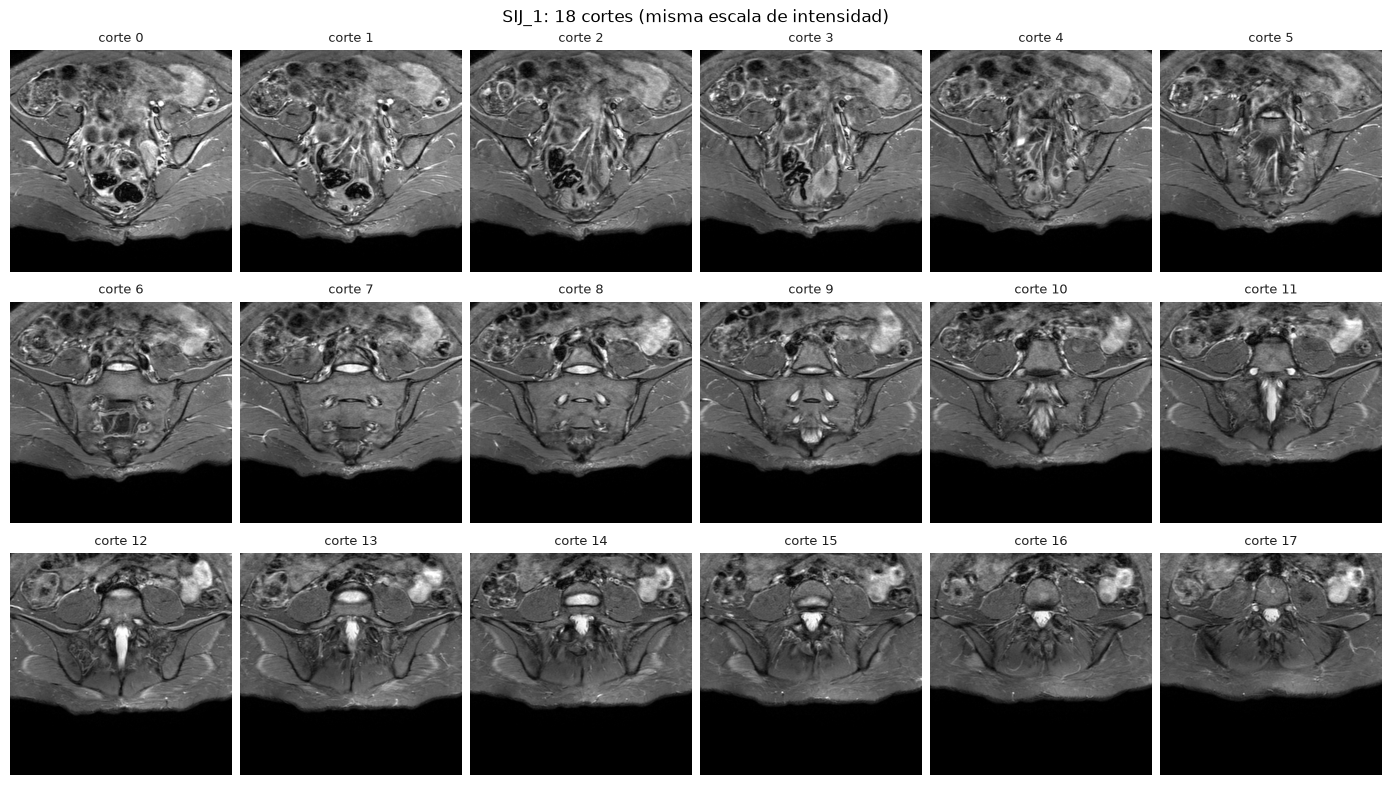

In [2]:
paths = list_local_volumes(RAW_DIR)
volumes = {p.name: read_raw(p) for p in paths}
assert len(volumes) == 9, f"Se esperaban 9 volúmenes en {RAW_DIR} y hay {len(volumes)}."

PCTS = (0.5, 1, 50, 99, 99.5)
filas = [
    "| Volumen | Forma (D,H,W) | Mín | Máx | p0.5 | p1 | p50 | p99 | p99.5 |",
    "|---|---|---:|---:|---:|---:|---:|---:|---:|",
]
for p in paths:
    v = volumes[p.name]
    q = np.percentile(v, PCTS)
    info = parse_raw_filename(p)
    assert v.shape == (info.slices, info.height, info.width), f"{p.name}: forma {v.shape} no coincide con el nombre."
    filas.append(
        f"| `SIJ_{info.patient}` | {v.shape} | {v.min()} | {v.max()} | "
        + " | ".join(f"{x:.0f}" for x in q) + " |"
    )
display(Markdown("\n".join(filas)))

vol1 = volumes[paths[0].name]
plot_mosaic(vol1, "SIJ_1")

## 4. Verificación del orden de los ejes

**Qué se hace.** El `.raw` no trae encabezado, así que el orden `(D, H, W)` y el *endianness* son una suposición que hay que comprobar. Para cada volumen se calcula la **diferencia absoluta media entre vecinos** en tres direcciones: entre cortes (`diff_slices`), entre filas (`diff_rows`) y entre columnas (`diff_cols`).

**Por qué.** En una imagen anatómica los píxeles vecinos *dentro* de un corte se parecen mucho (el plano es suave y de 0.6 mm), mientras que entre cortes la anatomía cambia más porque están separados 3 mm. Si el orden de ejes es el correcto, `diff_rows` y `diff_cols` deben ser **menores** que `diff_slices`. Si se leyera con el orden equivocado, las diferencias se invertirían (ruido). En `SIJ_1` se comprobó así: leído como `(D, H, W)` las diferencias fueron 8.2 (filas), 6.1 (columnas) y 22.7 (cortes); leído como `(H, W, D)`, 37.2, 28.6 y 6.2. Leído como *little-endian*, el máximo era 65 280, sin sentido, mientras que como *big-endian* el rango es 0–557.

Antes de la tabla se muestra el corte central de cada uno de los 9 volúmenes sin procesar (escala de intensidad propia por volumen): compruebe que todos muestran una pelvis en coronal oblicuo.

**Qué mirar.**
- En la tabla: en los 9 volúmenes, `diff_slices` debe ser la mayor de las tres. Si alguno falla, el `assert` detiene el notebook con un mensaje en español; no se intenta corregir solo.
- En la figura: a la izquierda, el corte central con una fila marcada; a la derecha, esa fila apilada a través de todos los cortes (`vol[:, fila, :]`), estirada 5 veces en vertical (3 mm / 0.6 mm) para respetar las proporciones reales. Se esperan **escalones horizontales**: cada uno es un corte de 3 mm. Esa imagen es mucho más tosca que el corte original, y por eso (sección 2.3) solo el plano adquirido sirve para segmentar. Aun así, las estructuras grandes deben seguir siendo continuas de un corte al siguiente.

| Volumen | diff entre cortes | diff entre filas | diff entre columnas | Orden correcto |
|---|---:|---:|---:|:---:|
| `SIJ_1` | 22.7 | 8.2 | 6.1 | True |
| `SIJ_2` | 55.7 | 19.2 | 15.3 | True |
| `SIJ_3` | 86.9 | 24.1 | 21.1 | True |
| `SIJ_4` | 64.0 | 21.8 | 17.4 | True |
| `SIJ_5` | 62.0 | 18.9 | 15.8 | True |
| `SIJ_6` | 68.7 | 21.2 | 17.2 | True |
| `SIJ_7` | 116.0 | 41.3 | 33.0 | True |
| `SIJ_8` | 111.7 | 39.7 | 32.1 | True |
| `SIJ_9` | 104.2 | 36.2 | 29.0 | True |

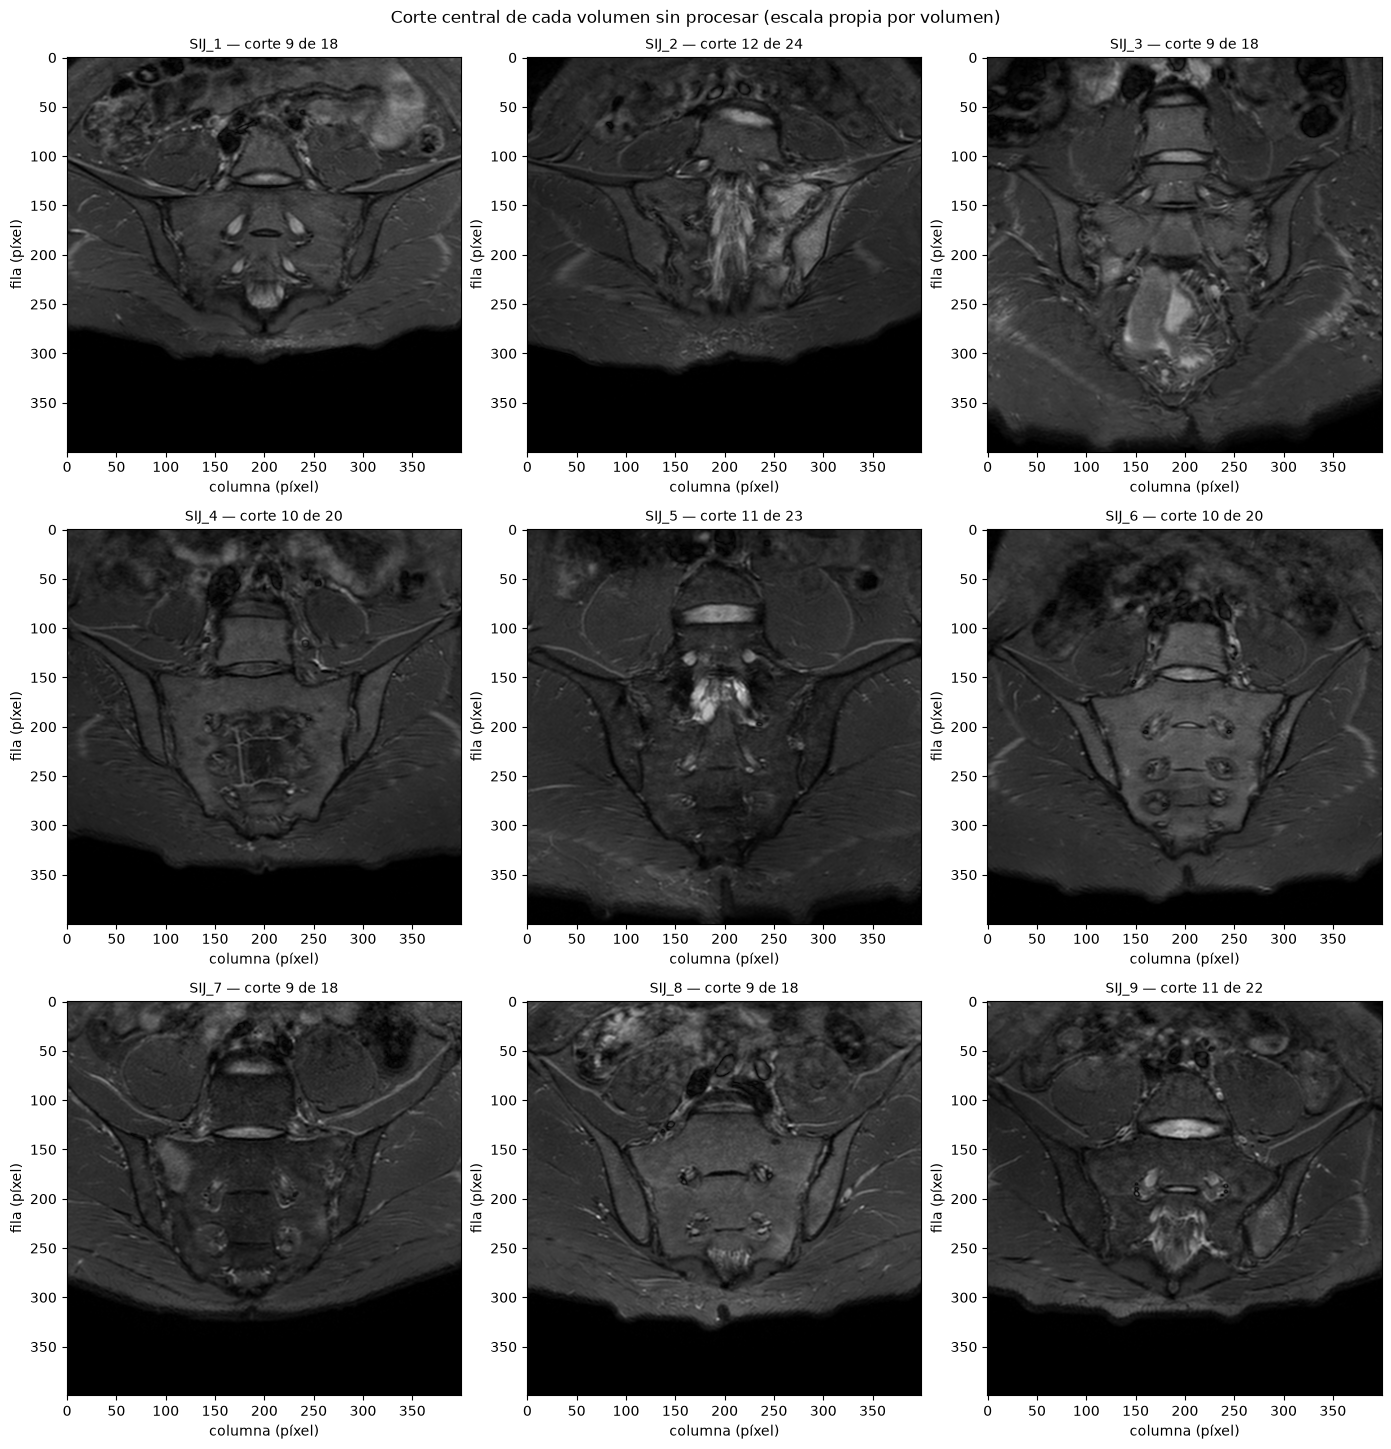

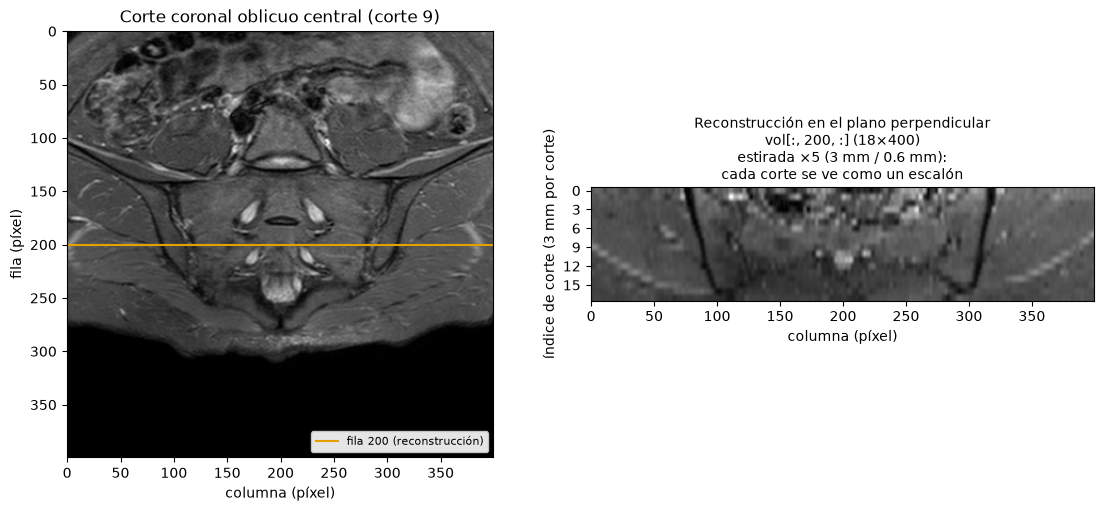

In [3]:
filas = [
    "| Volumen | diff entre cortes | diff entre filas | diff entre columnas | Orden correcto |",
    "|---|---:|---:|---:|:---:|",
]
fallos = []
for p in paths:
    c = axis_order_check(volumes[p.name])
    ok = c["diff_rows"] < c["diff_slices"] and c["diff_cols"] < c["diff_slices"]
    if not ok:
        fallos.append(p.name)
    filas.append(
        f"| `SIJ_{parse_raw_filename(p).patient}` | {c['diff_slices']:.1f} | "
        f"{c['diff_rows']:.1f} | {c['diff_cols']:.1f} | {ok} |"
    )
display(Markdown("\n".join(filas)))
assert not fallos, (
    "El orden de los ejes no es el esperado (cortes, filas, columnas) en: "
    f"{', '.join(fallos)}. Revisa el archivo .raw, su nombre y el endianness antes de continuar; "
    "el notebook no intenta corregirlo solo."
)

centrales = {f"SIJ_{parse_raw_filename(p).patient}": volumes[p.name] for p in paths}
display(plot_central_slices(centrales, "Corte central de cada volumen sin procesar (escala propia por volumen)"))
plot_orthogonal_check(vol1)

### Anisotropía de 5:1

El espaciado de los vóxeles es `(x, y, z) = (0.6, 0.6, 3.0)` mm (Gut et al., 2024): el paso entre cortes es 5 veces el paso dentro del corte. Los 3.0 mm en z son el **grosor de corte** informado por Gut et al. (2024); el artículo **no informa la separación entre cortes** (*gap*), así que usar 3.0 mm como paso entre cortes **supone que no hay separación**. Consecuencias que se usarán en el resto del proyecto:

- Entre un corte y el siguiente la anatomía cambia bastante más que dentro de un corte. Esto afecta a la propagación de la máscara en MedSAM2, que trata los cortes como fotogramas de video (Ravi et al., 2024; Ma et al., 2025), y a la U-Net 2.5D de la fase siguiente.
- Por eso los cortes deben mantenerse **en orden anatómico y contiguos**, y la intensidad se normalizará **por volumen, nunca por corte**; de lo contrario el mismo tejido cambiaría de brillo entre cortes y confundiría a la memoria del modelo.
- Cada corte se copiará a 3 canales idénticos solo para cumplir el formato RGB que espera el codificador preentrenado (Ravi et al., 2024); no aporta información nueva. Esto contrasta con la U-Net 2.5D, donde los 3 canales sí serán corte anterior, actual y siguiente.

**Siguiente paso (sección 5):** corrección de sesgo con N4 (Tustison et al., 2010), normalización por volumen a `uint8` y reproducción de la entrada de MedSAM2.

## 5. Corrección del campo de sesgo (N4)

### 5.1 Qué es el campo de sesgo y por qué se corrige antes de normalizar

**Qué se hace.** Se estima, para cada volumen, un **campo de sesgo** (*bias field*): un mapa suave y de variación lenta, con valores alrededor de 1, por el que el equipo multiplicó la imagen sin que eso sea anatomía. La imagen corregida es la imagen original dividida entre ese campo. Se usa el algoritmo **N4** (Tustison et al., 2010), la versión mejorada del método N3 (Sled et al., 1998), a través de SimpleITK.

**Por qué ocurre.** En RM la sensibilidad de la bobina receptora no es uniforme (aquí, una bobina de torso de 8 canales; Gut et al., 2024), y también influyen otras fuentes, como la inhomogeneidad del campo de radiofrecuencia. El resultado es que el **mismo tejido** aparece más brillante en una zona de la imagen que en otra (Sled et al., 1998). Eso es un problema porque queremos que el brillo signifique tejido, no posición.

**Por qué antes de normalizar.** N4 supone un modelo **multiplicativo** sobre intensidades físicas positivas (imagen = tejido × campo). Si se recortara y reescalara a 0–255 antes, el recorte sería no lineal y el modelo multiplicativo dejaría de cumplirse; además, los percentiles se calcularían sobre intensidades todavía sesgadas. Por eso el orden del flujo es: **máscara, N4, recorte, normalización**.

**Cómo se mide si funcionó.** Con el **coeficiente de variación (CV = desviación estándar / media)** de la intensidad dentro del cuerpo, antes y después. Si el sesgo disminuye, el CV debería bajar. Es un indicador **imperfecto**: el CV también refleja el contraste anatómico real (hueso, grasa, líquido), así que una bajada pequeña no significa que N4 falló, y una bajada grande no prueba por sí sola que la corrección sea buena. Por eso se acompaña de la inspección visual del campo.

In [4]:
import json
import time
from datetime import datetime, timezone

from sij_prep.download import sha256_of
from sij_prep.intensity import (
    body_mask,
    coefficient_of_variation,
    n4_correct,
    normalize_to_uint8,
    percentile_bounds,
    saturation_fraction,
)
from sij_prep.io import load_nifti, load_npz, save_params_json, save_volume
from sij_prep.model_view import suggest_key_slice, to_model_input
from sij_prep.viz import (
    plot_clipping_comparison,
    plot_histograms_before_after,
    plot_key_slice,
    plot_mask_comparison,
    plot_model_input,
    plot_n4_trio,
    plot_volume_distributions,
)

# Nombre corto de cada volumen: "SIJ_1", "SIJ_2", ...
names = {p.name: f"SIJ_{parse_raw_filename(p).patient}" for p in paths}
vols_f = {names[n]: v.astype(np.float32) for n, v in volumes.items()}  # float32: lo que espera N4
mid1 = vols_f["SIJ_1"].shape[0] // 2  # corte central de SIJ_1

### 5.2 La máscara del cuerpo: umbral bajo frente a Otsu

**Qué se hace.** N4 debe ajustarse solo con los píxeles del **cuerpo**, no con el fondo negro. Se comparan dos máscaras sobre el corte central de `SIJ_1`:
- **Otsu:** el umbral que mejor separa dos clases en el histograma.
- **Umbral bajo** (`MASK_METHOD = "low_threshold"`): `vol > 0.05 × percentil 99` del volumen. En ambas se rellenan los huecos corte a corte y se conserva solo la mayor componente conexa 3D.

**Por qué el umbral bajo.** En STIR la grasa está **suprimida**: el tejido subcutáneo y la médula grasa son oscuros pero siguen siendo cuerpo. Otsu separa "brillante" de "oscuro" y tiende a dejar fuera esos tejidos oscuros. El umbral bajo solo separa "hay señal" de "no hay señal" y los incluye.

**Qué mirar.**
- En la tabla: la máscara de umbral bajo contiene el 100 % de la de Otsu y cubre más volumen (0.739 frente a 0.711). Es decir, Otsu no aporta nada que el umbral bajo no tenga, y deja fuera un 2.8 % adicional del volumen.
- En la figura: el contorno azul sólido (umbral bajo) sigue el borde exterior del cuerpo, sobre todo el borde posterior contra el fondo negro. El contorno naranja punteado (Otsu) coincide en buena parte del borde, pero en el borde posterior queda unos píxeles **por dentro** del azul (deja fuera la franja oscura de tejido blando) y, arriba y en el flanco izquierdo, dibuja contornos alrededor de líneas oscuras dentro del cuerpo: son zonas oscuras que Otsu trata como "no cuerpo". Por eso `MASK_METHOD` es `"low_threshold"`. La máscara se calcula sobre la imagen **original**, antes de N4.

| Máscara | Fracción del volumen | Fracción de la máscara de Otsu que contiene |
|---|---:|---:|
| Umbral bajo | 0.739 | 1.000 |
| Otsu | 0.711 | 1.000 |

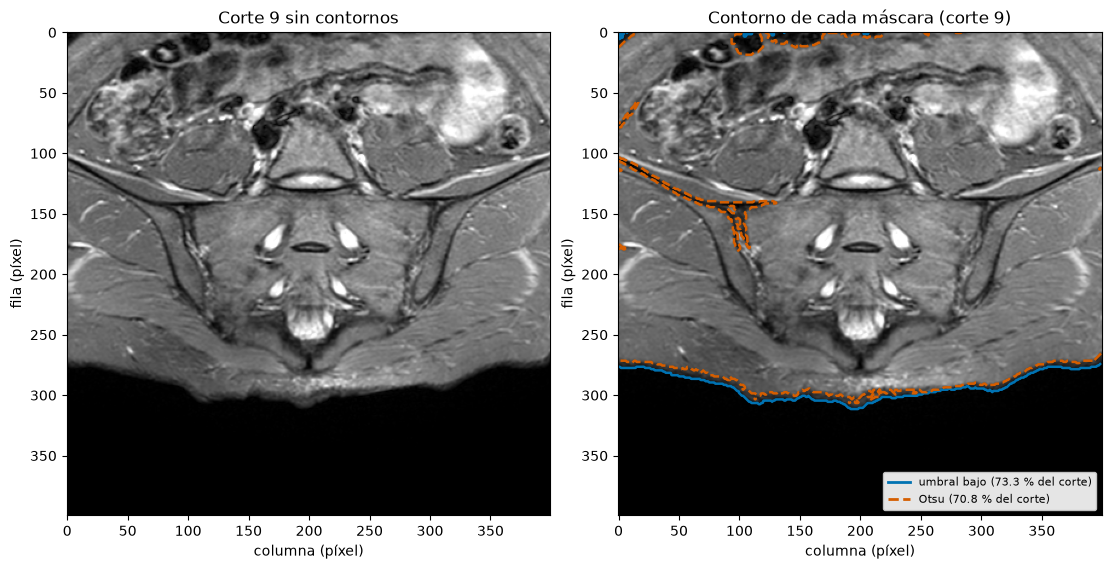

In [5]:
v1 = vols_f["SIJ_1"]
mask_low = body_mask(v1, method="low_threshold")
mask_otsu = body_mask(v1, method="otsu")

en_ambas = (mask_low & mask_otsu).sum() / mask_otsu.sum()
display(Markdown(
    "| Máscara | Fracción del volumen | Fracción de la máscara de Otsu que contiene |\n|---|---:|---:|\n"
    f"| Umbral bajo | {mask_low.mean():.3f} | {en_ambas:.3f} |\n"
    f"| Otsu | {mask_otsu.mean():.3f} | 1.000 |"
))

plot_mask_comparison(v1, {"umbral bajo": mask_low, "Otsu": mask_otsu}, mid1)

### 5.3 Parámetros de N4 y resultados en los 9 volúmenes

**Qué se hace.** Se aplica `n4_correct` a cada volumen en `float32`, con el espaciado `(0.6, 0.6, 3.0)` mm y la máscara anterior. Se suma 1 a la imagen para evitar ceros en el fondo y se devuelven la imagen corregida y el campo de sesgo (siempre positivo). Dos decisiones de parámetros:

- **Reducción `[4, 4, 1]` (`N4_SHRINK = 4`).** Para acelerar, N4 se ajusta sobre una versión reducida de la imagen y luego el campo se evalúa a resolución completa. Se reduce 4 veces en x e y (el vóxel pasa de 0.6 a 2.4 mm, parecido al corte de 3 mm), pero **no en z**: con solo 18 a 24 cortes de 3 mm, reducir z dejaría 4 a 6 cortes, muy pocos para ajustar el campo.
- **3 niveles de ajuste, `(50, 50, 50)`, y no 4.** Cada nivel afina el campo con más detalle. En una prueba previa sobre `SIJ_1` con 4 niveles, el campo dejó de ser un gradiente suave y formó una mancha caliente sobre el contenido intestinal brillante, es decir, **seguía la anatomía**. Un campo así dividiría señal real (por ejemplo, edema) y la aplanaría. Con 3 niveles el campo es un gradiente suave y el CV sigue bajando en los 9 volúmenes. La contrapartida es que la bajada del CV es menor que con 4 niveles (en esa prueba, `SIJ_1` pasó de 0.383 a 0.325 con 4 niveles y a 0.348 con 3); es un precio deliberado.

**Qué mirar.**
- En la tabla: la columna "¿Baja?". Si en algún volumen el CV no baja, el notebook lo escribe debajo de la tabla; no se oculta. La columna del campo muestra su rango dentro de la máscara: debe ser cercano a 1 (aquí, entre 0.59 y 1.58), no valores extremos.
- La mejora **no es pareja**: va de −2.3 % en `SIJ_7` a −18.0 % en `SIJ_4`. En `SIJ_7` el sesgo es pequeño, y eso se confirma en la figura siguiente.
- El tiempo por volumen es de unos pocos segundos.

In [6]:
masks, corrected, bias = {}, {}, {}
filas = [
    "| Volumen | CV antes | CV después | Cambio | ¿Baja? | Campo de sesgo (mín–máx) | Tiempo (s) |",
    "|---|---:|---:|---:|:---:|---:|---:|",
]
no_bajan = []
for k, v in vols_f.items():
    m = body_mask(v, method=MASK_METHOD)
    t0 = time.perf_counter()
    c, b = n4_correct(v, m, shrink_factor=N4_SHRINK, max_iterations=N4_ITERS)
    seg = time.perf_counter() - t0
    assert np.isfinite(c).all() and (b > 0).all(), f"{k}: N4 produjo valores no finitos o un campo no positivo."
    cv0, cv1 = coefficient_of_variation(v, m), coefficient_of_variation(c, m)
    baja = cv1 < cv0
    if not baja:
        no_bajan.append(k)
    masks[k], corrected[k], bias[k] = m, c, b
    filas.append(
        f"| `{k}` | {cv0:.4f} | {cv1:.4f} | {100 * (cv1 - cv0) / cv0:+.1f} % | {baja} | "
        f"{b[m].min():.2f}–{b[m].max():.2f} | {seg:.1f} |"
    )
display(Markdown("\n".join(filas)))
if no_bajan:
    display(Markdown(f"**Atención:** el CV no bajó en {', '.join(no_bajan)}."))
else:
    display(Markdown(f"El CV bajó en los {len(vols_f)} volúmenes."))

| Volumen | CV antes | CV después | Cambio | ¿Baja? | Campo de sesgo (mín–máx) | Tiempo (s) |
|---|---:|---:|---:|:---:|---:|---:|
| `SIJ_1` | 0.3828 | 0.3484 | -9.0 % | True | 0.73–1.44 | 1.6 |
| `SIJ_2` | 0.4368 | 0.3670 | -16.0 % | True | 0.75–1.58 | 2.3 |
| `SIJ_3` | 0.4344 | 0.3788 | -12.8 % | True | 0.70–1.45 | 1.9 |
| `SIJ_4` | 0.4392 | 0.3603 | -18.0 % | True | 0.59–1.47 | 2.3 |
| `SIJ_5` | 0.4184 | 0.3908 | -6.6 % | True | 0.67–1.39 | 2.0 |
| `SIJ_6` | 0.4091 | 0.3489 | -14.7 % | True | 0.72–1.52 | 1.9 |
| `SIJ_7` | 0.4034 | 0.3940 | -2.3 % | True | 0.89–1.31 | 0.9 |
| `SIJ_8` | 0.3957 | 0.3735 | -5.6 % | True | 0.79–1.24 | 1.4 |
| `SIJ_9` | 0.4437 | 0.4153 | -6.4 % | True | 0.75–1.39 | 2.1 |

El CV bajó en los 9 volúmenes.

**Qué mirar en el trío (corte central, filas: original, campo de sesgo, corregida, perfil).**
- **Arriba a la izquierda:** el corte original con el contorno de la máscara (naranja) y, con una línea punteada, la fila 200, que cruza el sacro.
- **Arriba a la derecha:** el campo de sesgo como mapa de calor. Debe ser **suave y de baja frecuencia**, sin formas que recuerden estructuras anatómicas. Cuidado con la zona oscura de abajo: está en el fondo negro, fuera de la máscara, y el campo allí es solo una extrapolación; no significa nada.
- **Abajo a la izquierda:** la imagen corregida, a la misma escala de gris que la original. Debe verse igual de natural, sin halos ni zonas aplanadas.
- **Abajo a la derecha:** el perfil de intensidad a lo largo de la fila 200, antes y después. Las dos curvas deben tener la misma forma; la corrección solo debe desplazar, de manera suave, el nivel.

**`SIJ_1`.** El campo va de 0.75 a 1.2 en este corte: más alto arriba a la derecha (sobre el intestino) y más bajo abajo a la izquierda. En el perfil, la corregida queda algo por encima del original en la zona izquierda (donde el campo es menor que 1) y por debajo hacia la derecha (donde es mayor que 1); los picos y valles están en las mismas posiciones, es decir, la forma del perfil no cambia.

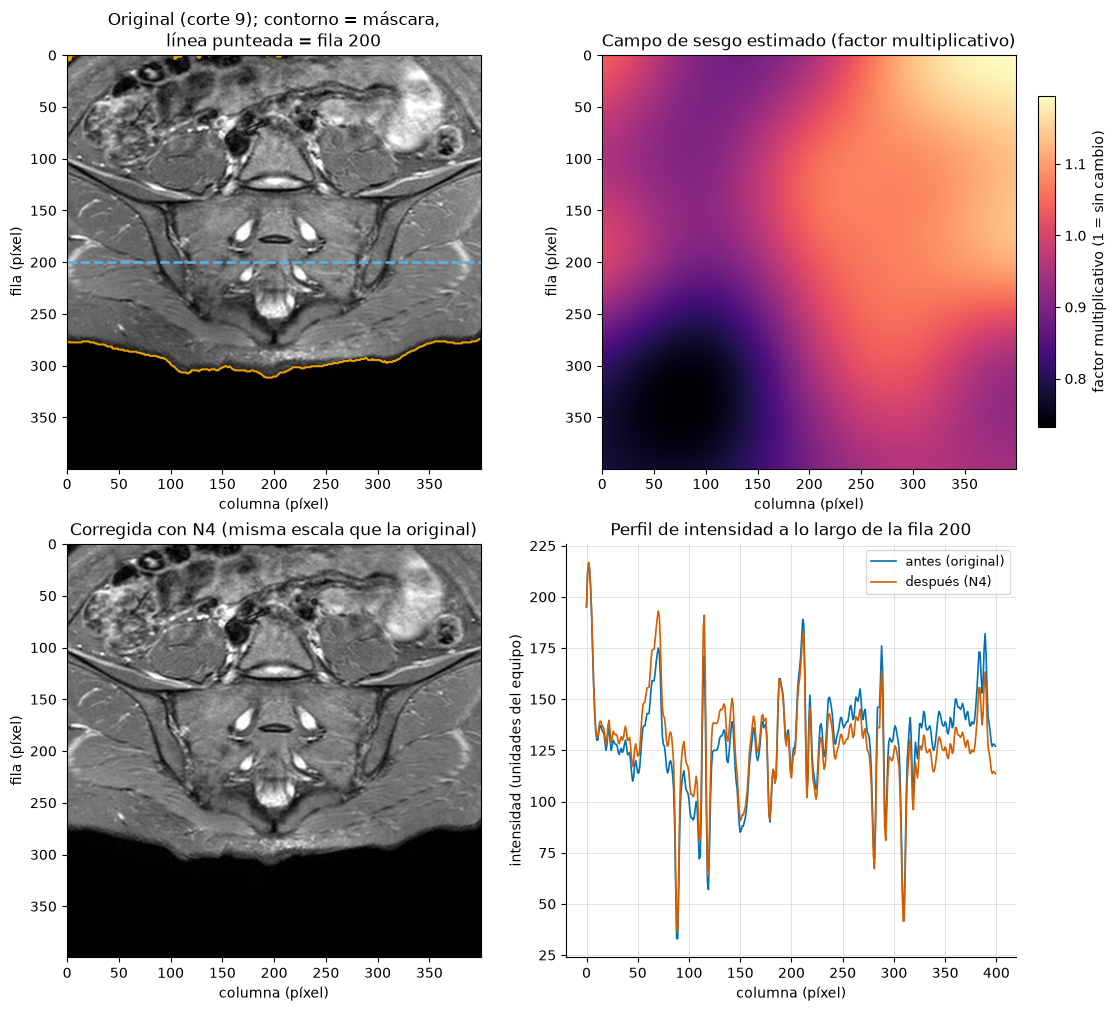

In [7]:
k = "SIJ_1"
m = masks[k]
fila = 200  # fila que cruza el sacro, para el perfil de intensidad
fig = plot_n4_trio(vols_f[k], bias[k], corrected[k], m, mid1, line_row=fila)
display(fig)

**`SIJ_7`**, el volumen donde el CV bajó menos (−2.3 %). El campo es suave y su rango en este corte es estrecho (0.90 a 1.16): más oscuro en el centro, más alto en el borde derecho y con un lóbulo cálido en la esquina inferior izquierda (cerca de 1.08, en parte dentro del cuerpo). Las curvas del perfil casi se superponen, con diferencias pequeñas a la derecha. Es coherente con la poca bajada del CV: el sesgo estimado es pequeño y el cambio sobre la imagen también.

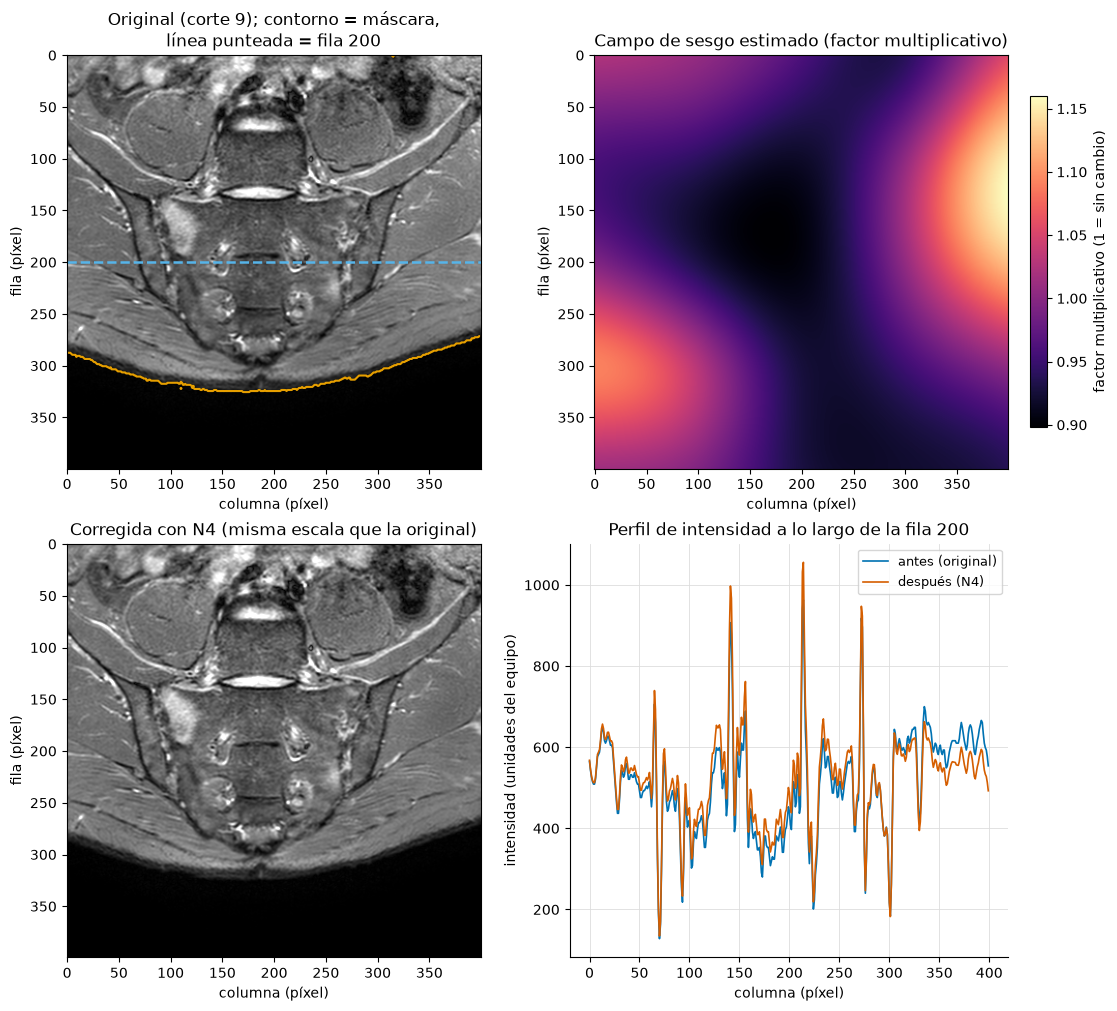

In [8]:
k = "SIJ_7"
m = masks[k]
mid = vols_f[k].shape[0] // 2
fila = 200
fig = plot_n4_trio(vols_f[k], bias[k], corrected[k], m, mid, line_row=fila)
display(fig)

## 6. Comparación de criterios de recorte

**Qué se hace.** Para pasar de las intensidades del equipo a `uint8` 0–255 hay que decidir qué valor será 0 y cuál será 255. Se compara recortar a los percentiles **(0, 100)** (sin recorte: mínimo y máximo), **(0.5, 99.5)** y **(1, 99)**. Los percentiles se calculan **dentro de la máscara del cuerpo**, sobre la imagen ya corregida con N4, y siempre **por volumen**.

**Por qué recortar.** La RM no tiene escala de intensidad fija: el valor numérico de un tejido cambia entre exámenes, así que cada volumen debe llevarse a un rango común (Nyúl & Udupa, 1999; Shinohara et al., 2014). Sin recorte, unos pocos vóxeles extremos (por ejemplo, vasos o líquido muy brillante) definen el máximo y comprimen todo el contraste útil en unos pocos niveles de gris. Con recorte, ese contraste se reparte mejor, a costa de **saturar** los vóxeles más brillantes (todos los que están por encima de `hi` pasan a 255) y los más oscuros (los que están por debajo de `lo` pasan a 0).

**El riesgo en STIR.** En STIR el **edema de la médula ósea** es brillante y puede estar entre los valores más altos del volumen. Si el recorte superior es demasiado agresivo, el edema puede quedar **plano** (todo en 255): se pierde su textura y su borde, que es justo lo que queremos segmentar. Hay que verificarlo con las figuras, no suponerlo.

In [9]:
CRITERIOS = [(0, 100), (0.5, 99.5), (1, 99)]
filas = [
    "| Volumen | " + " | ".join(f"({lo:g}–{hi:g}) hi" for lo, hi in CRITERIOS) + " | "
    + " | ".join(f"({lo:g}–{hi:g}) % saturado" for lo, hi in CRITERIOS) + " | máx / hi (0.5–99.5) |",
    "|---|" + "---:|" * (2 * len(CRITERIOS) + 1),
]
for k in vols_f:
    his, sats = [], []
    for lo_p, hi_p in CRITERIOS:
        _, hi = percentile_bounds(corrected[k], lo_p, hi_p, masks[k])
        his.append(f"{hi:.0f}")
        sats.append(f"{100 * saturation_fraction(corrected[k], hi, masks[k]):.2f}")
    razon = percentile_bounds(corrected[k], 0, 100, masks[k])[1] / percentile_bounds(corrected[k], 0.5, 99.5, masks[k])[1]
    filas.append(f"| `{k}` | " + " | ".join(his) + " | " + " | ".join(sats) + f" | {razon:.2f} |")
display(Markdown("\n".join(filas)))

| Volumen | (0–100) hi | (0.5–99.5) hi | (1–99) hi | (0–100) % saturado | (0.5–99.5) % saturado | (1–99) % saturado | máx / hi (0.5–99.5) |
|---|---:|---:|---:|---:|---:|---:|---:|
| `SIJ_1` | 456 | 282 | 254 | 0.00 | 0.50 | 1.00 | 1.62 |
| `SIJ_2` | 1326 | 777 | 706 | 0.00 | 0.50 | 1.00 | 1.71 |
| `SIJ_3` | 1333 | 843 | 761 | 0.00 | 0.50 | 1.00 | 1.58 |
| `SIJ_4` | 1629 | 878 | 782 | 0.00 | 0.50 | 1.00 | 1.86 |
| `SIJ_5` | 1578 | 846 | 681 | 0.00 | 0.50 | 1.00 | 1.87 |
| `SIJ_6` | 1392 | 793 | 691 | 0.00 | 0.50 | 1.00 | 1.76 |
| `SIJ_7` | 2590 | 1482 | 1287 | 0.00 | 0.50 | 1.00 | 1.75 |
| `SIJ_8` | 2121 | 1405 | 1215 | 0.00 | 0.50 | 1.00 | 1.51 |
| `SIJ_9` | 2360 | 1535 | 1230 | 0.00 | 0.50 | 1.00 | 1.54 |

**Qué mirar en la tabla.**
- Las columnas `hi` son el valor de intensidad que pasa a 255 con cada criterio. Cambian mucho entre volúmenes (en (0.5–99.5), de 282 en `SIJ_1` a 1535 en `SIJ_9`), otra razón para recortar por volumen.
- El **% saturado es casi una tautología**: por definición, con percentil alto 99.5 satura el 0.5 % de los vóxeles y con 99 satura el 1 %, en todos los volúmenes (con (0, 100) no satura nada). Por eso esa columna **no dice qué se satura**, solo cuánto; lo que importa es **dónde** cae ese 0.5 % o 1 %, y eso se ve en las figuras.
- La última columna, `máx / hi (0.5–99.5)`, dice cuánto rango queda aplastado por encima de `hi`: el máximo del volumen es entre 1.5 y 1.9 veces `hi`. Todo ese tramo se vuelve 255.

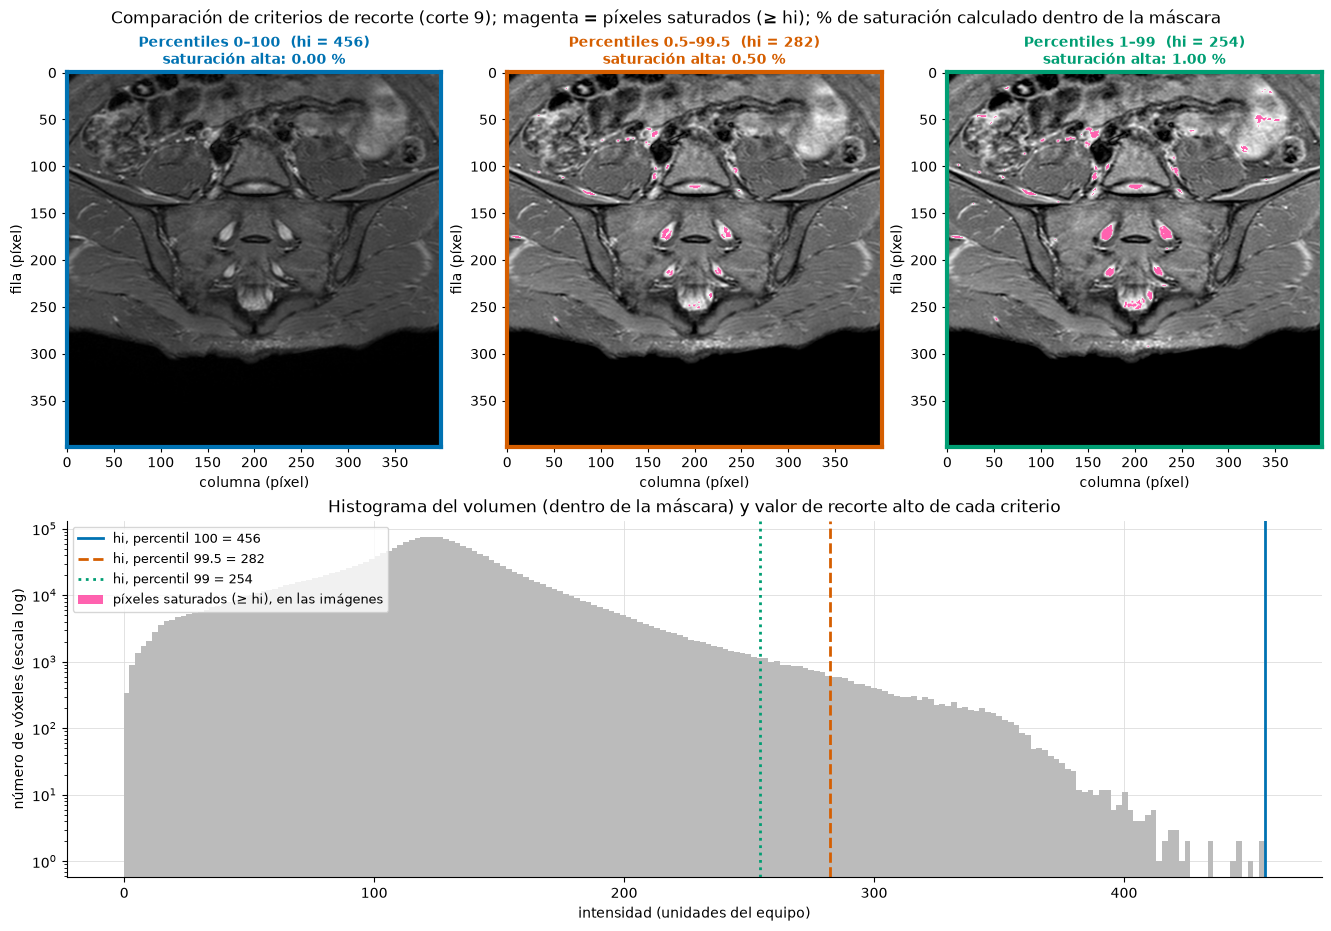

In [10]:
display(plot_clipping_comparison(corrected["SIJ_1"], CRITERIOS, mid1, masks["SIJ_1"]))

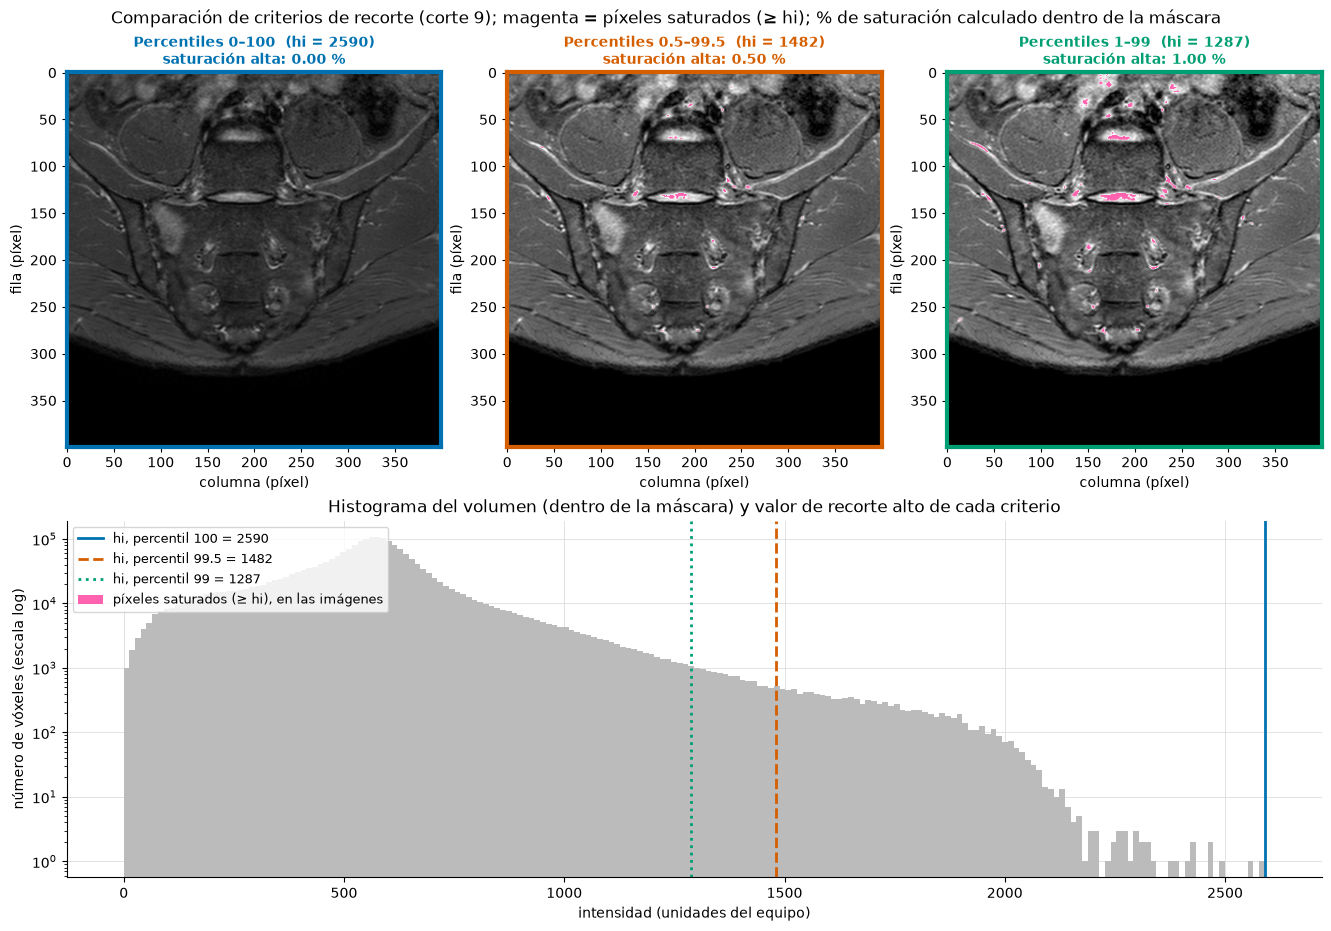

In [11]:
mid7 = corrected["SIJ_7"].shape[0] // 2
display(plot_clipping_comparison(corrected["SIJ_7"], CRITERIOS, mid7, masks["SIJ_7"]))

**Qué mirar en cada figura de comparación (corte central).**
- Cada columna es un criterio; los píxeles **saturados** (≥ `hi`) están pintados de **magenta** sobre la imagen. El histograma de abajo (escala logarítmica) muestra dónde cae el `hi` de cada criterio.
- **Revise explícitamente que las zonas brillantes que le interesan (edema, líquido en la articulación) no queden como manchas planas de magenta.** Una mancha pequeña y puntual es aceptable; una región extensa pintada de magenta, no.
- Con (0, 100) no hay magenta, porque nada se satura. Con (1, 99) el magenta crece respecto a (0.5, 99.5): es la opción más agresiva.

**Lo que se ve en `SIJ_1` (corte central).** Con (0.5, 99.5) el magenta cae sobre focos pequeños y redondeados: sobre todo los **forámenes sacros** (las estructuras brillantes ovaladas en el centro, que contienen líquido) y algunos puntos del contenido intestinal y de vasos arriba. No hay una región extensa pintada. Con (1, 99) esos mismos focos se agrandan y aparecen más puntos en el intestino brillante de la parte superior derecha.

**Lo que se ve en `SIJ_7` (corte central).** Con (0.5, 99.5) el magenta es escaso: una estructura horizontal brillante cerca de la línea media (alrededor de la fila 130) y puntos dispersos pequeños. Con (1, 99) esa estructura se llena más y aparecen puntos adicionales alrededor. Hay además una zona brillante en el hueso, a la izquierda del sacro (cerca de la columna 115 y la fila 170), que podría corresponder a edema (no se ha confirmado): **no queda pintada de magenta con ninguno de los dos criterios**, es decir, conserva su textura.

**Conclusión y límites.** En estos dos cortes, el criterio (0.5, 99.5) satura focos pequeños (líquido, vasos, intestino) y no regiones extensas, y es más conservador que (1, 99); por eso se mantiene como valor por defecto (`CLIP_LOW_PCT`, `CLIP_HIGH_PCT`). Pero esto **no está cerrado**: se revisaron 2 volúmenes y 1 corte por volumen, y en esos cortes no se identificó una zona de edema extensa. Antes de dar el criterio por definitivo hay que repetir la revisión en los cortes con lesión, idealmente con apoyo clínico (pendiente del §8 del diseño). Como el criterio es un parámetro al inicio del notebook, cambiarlo y volver a ejecutar es barato.

## 7. Normalización final por volumen

**Qué se hace.** Con `normalize_to_uint8`, cada volumen (ya corregido con N4) se recorta a `[lo, hi]`, con `lo` y `hi` los percentiles `CLIP_LOW_PCT` y `CLIP_HIGH_PCT` **dentro de la máscara**, y se reescala **linealmente** a 0–255 (`lo` pasa a 0 y `hi` a 255) y se guarda como `uint8`. Se hace **sobre todo el volumen a la vez, nunca corte por corte**: un solo `lo` y un solo `hi` por volumen.

**Por qué por volumen y con la máscara.**
- Normalizar por corte cambiaría el brillo del mismo tejido de un corte a otro, y confundiría a la memoria de MedSAM2, que propaga la máscara entre cortes (Ravi et al., 2024; Ma et al., 2025).
- Si no se pasa la máscara, el fondo negro (entre 8 % y 26 % según el volumen) entra en los percentiles y desplaza `lo` hacia abajo.

**Qué mirar.**
- En la tabla: `uint8` con mínimo 0 y máximo 255 en los 9 volúmenes, y `lo` y `hi` distintos en cada uno. El % saturado arriba es 0.50 % en todos, por lo explicado en la sección 6.
- En los histogramas de `SIJ_1` (dentro de la máscara): a la izquierda, la distribución original con las líneas `lo` y `hi`; a la derecha, el resultado. La forma se conserva (es una transformación lineal en la zona intermedia), con **dos barras extra en los extremos**: en 0 y en 255 se acumulan los vóxeles recortados, aproximadamente un 0.5 % en cada lado.
- En los diagramas de cajas: antes de normalizar, las medianas de los volúmenes van desde unas 120 (`SIJ_1`) hasta unas 560 (`SIJ_7`); después, todos están en el mismo rango de 0–255, con medianas entre unas 70 y unas 100. **Quedan comparables, pero no idénticos**: la normalización por percentiles alinea los extremos, no la mediana, y cada volumen tiene una forma de distribución distinta.

| Volumen | lo (p0.5) | hi (p99.5) | dtype | mín | máx | % saturado arriba |
|---|---:|---:|---|---:|---:|---:|
| `SIJ_1` | 14.5 | 282.3 | uint8 | 0 | 255 | 0.50 |
| `SIJ_2` | 43.7 | 776.5 | uint8 | 0 | 255 | 0.50 |
| `SIJ_3` | 32.2 | 842.8 | uint8 | 0 | 255 | 0.50 |
| `SIJ_4` | 60.7 | 877.7 | uint8 | 0 | 255 | 0.50 |
| `SIJ_5` | 39.0 | 846.0 | uint8 | 0 | 255 | 0.50 |
| `SIJ_6` | 35.2 | 792.7 | uint8 | 0 | 255 | 0.50 |
| `SIJ_7` | 55.8 | 1481.6 | uint8 | 0 | 255 | 0.50 |
| `SIJ_8` | 59.1 | 1404.6 | uint8 | 0 | 255 | 0.50 |
| `SIJ_9` | 63.4 | 1534.8 | uint8 | 0 | 255 | 0.50 |

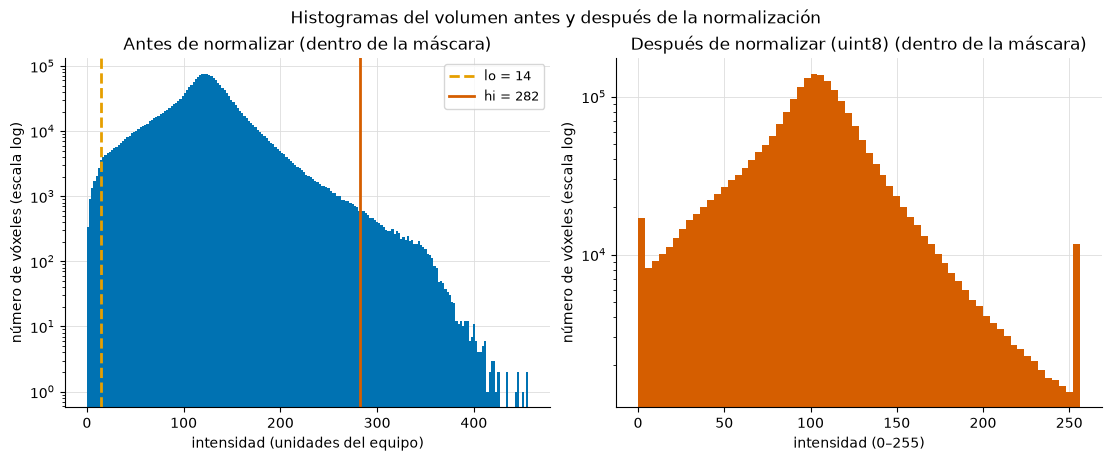

In [12]:
u8, info = {}, {}
for k in vols_f:
    # Siempre con la máscara: así el fondo no entra en los percentiles.
    u8[k], info[k] = normalize_to_uint8(
        corrected[k], low_pct=CLIP_LOW_PCT, high_pct=CLIP_HIGH_PCT, mask=masks[k]
    )

filas = [
    f"| Volumen | lo (p{CLIP_LOW_PCT:g}) | hi (p{CLIP_HIGH_PCT:g}) | dtype | mín | máx | % saturado arriba |",
    "|---|---:|---:|---|---:|---:|---:|",
]
for k in vols_f:
    sat = 100 * saturation_fraction(corrected[k], info[k]["hi"], masks[k])
    filas.append(
        f"| `{k}` | {info[k]['lo']:.1f} | {info[k]['hi']:.1f} | {u8[k].dtype} | "
        f"{u8[k].min()} | {u8[k].max()} | {sat:.2f} |"
    )
display(Markdown("\n".join(filas)))

display(plot_histograms_before_after(corrected["SIJ_1"], u8["SIJ_1"], info["SIJ_1"]["lo"], info["SIJ_1"]["hi"], mask=masks["SIJ_1"]))

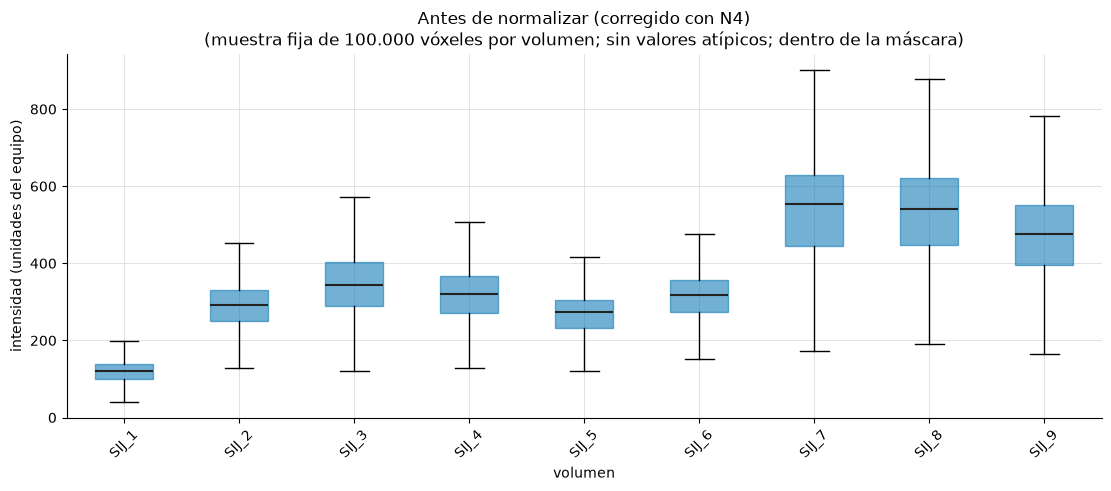

In [13]:
display(plot_volume_distributions(
    corrected, "Antes de normalizar (corregido con N4)", masks=masks,
    ylabel="intensidad (unidades del equipo)",
))

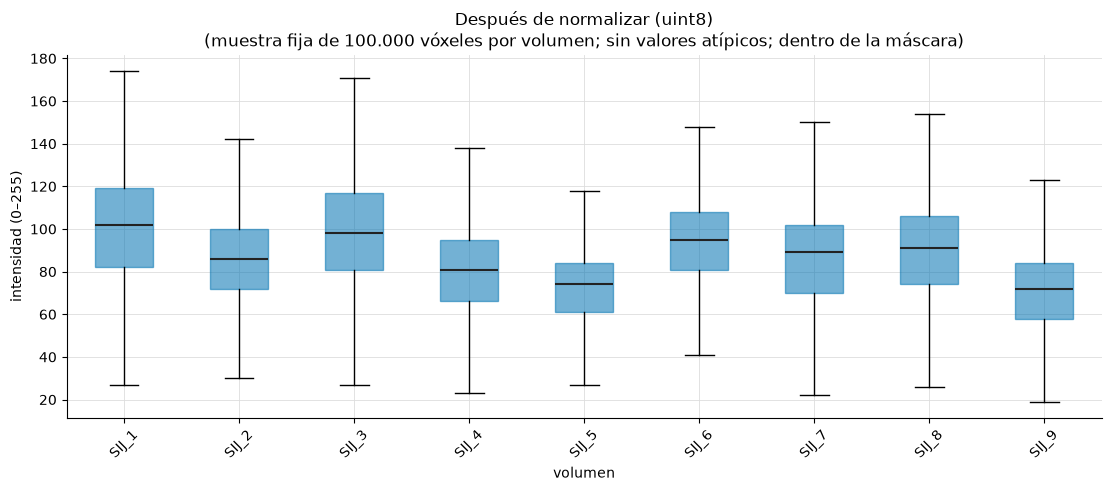

In [14]:
display(plot_volume_distributions(u8, "Después de normalizar (uint8)", masks=masks))

## 8. Lo que ve el modelo

**Qué se hace.** Se reproduce, solo para visualizar, lo que MedSAM2 hace por dentro con cada corte (Ma et al., 2025; código del repositorio del modelo): `Image.fromarray(s).convert("RGB").resize((512, 512))`, luego dividir entre 255 y aplicar la normalización de ImageNet (media `(0.485, 0.456, 0.406)`, desviación `(0.229, 0.224, 0.225)`). Esto **no se guarda**: el modelo lo hace solo; lo que guardamos es el `uint8` de la sección anterior.

**Por qué.** Para entender qué recibe realmente el modelo:
- **3 canales idénticos.** El codificador de imagen se preentrenó con fotos en color (RGB) y su primera capa espera 3 canales. Una RM es monocanal, así que el mismo corte se copia 3 veces. No hay información nueva; es una adaptación de formato (Ravi et al., 2024).
- **512×512.** Se redimensiona de 400×400 a 512×512 con el filtro por defecto de Pillow.
- **Normalización de ImageNet.** Se aplica la media y la desviación del preentrenamiento, por canal; por eso los 3 canales difieren entre sí solo en esas constantes.
- **La tercera dimensión viene de la memoria, no de los canales.** El volumen se trata como un video: cada corte es un fotograma y un banco de memoria propaga la máscara de un corte al siguiente (Ravi et al., 2024; Ma et al., 2025). Es distinto de la U-Net 2.5D de la fase siguiente, donde los 3 canales sí serán corte anterior, actual y siguiente.

**Qué mirar.** De izquierda a derecha: el corte original `uint8` de 400×400; los tres canales normalizados de 512×512, con sus valores mínimo, máximo y media (distintos por canal solo por las constantes de ImageNet); y la imagen desnormalizada, que debe verse como la original. Los tres canales se ven **iguales a simple vista**, y eso es lo correcto.

Entrada del modelo: forma (3, 512, 512), dtype float32


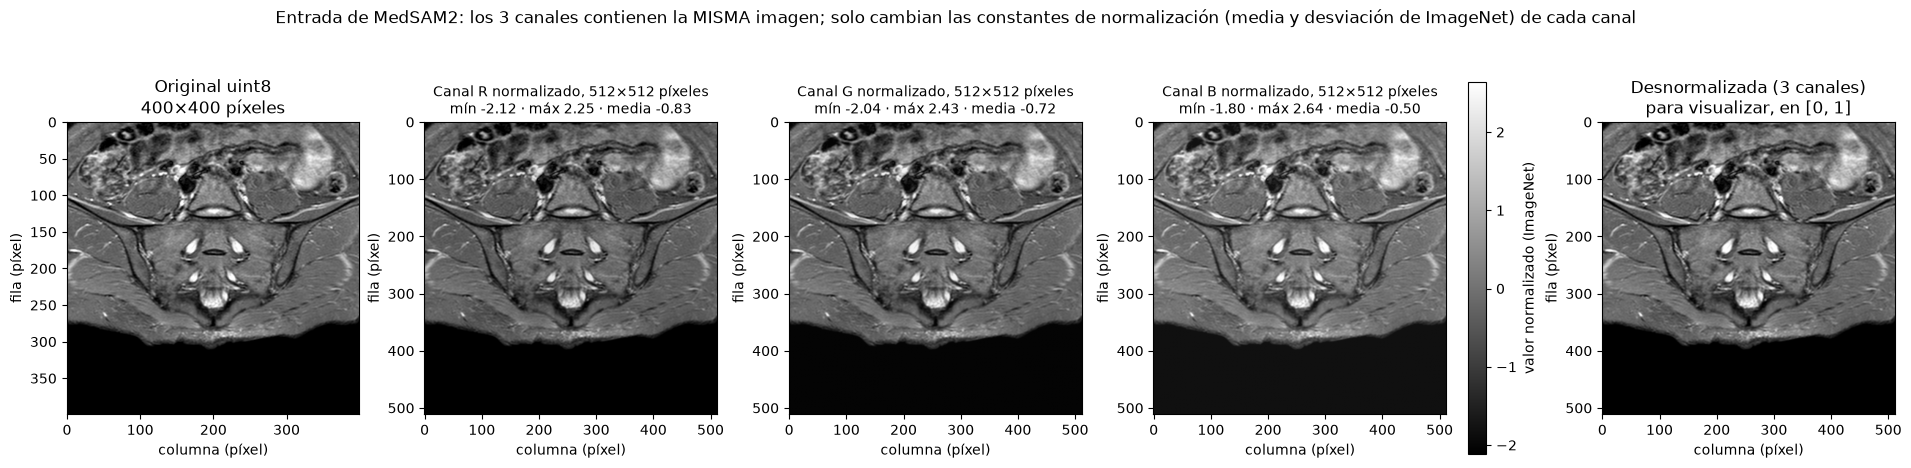

In [15]:
s = u8["SIJ_1"][mid1]
x = to_model_input(s)
print(f"Entrada del modelo: forma {x.shape}, dtype {x.dtype}")
plot_model_input(s, x)

## 9. Guardado de los volúmenes procesados

**Qué se hace.** Cada volumen `uint8` se guarda en `data/processed/` en dos formatos, con el nombre `SIJ_<n>`:
- **`.npz`**, con el arreglo `imgs` `(D, H, W)` `uint8` y el `spacing` `(x, y, z)`. Es el formato de la variante eficiente de MedSAM2.
- **`.nii.gz`** (NIfTI), con el espaciado `(0.6, 0.6, 3.0)` mm en el encabezado, dirección identidad y origen 0. La orientación del paciente **no está documentada** en el `.raw`, así que no se inventa; MedSAM2 solo usa el arreglo.

Además se escribe `preprocessing_params.json` con la **trazabilidad**: percentiles de recorte, método de máscara, parámetros de N4, espaciado y, por cada volumen, el archivo de origen y su `sha256`, la forma, `lo`, `hi`, el CV antes y después, la fracción saturada y el corte clave sugerido. Con eso se puede saber exactamente cómo se produjo cada archivo. Re-ejecutar el notebook sobrescribe los archivos con el mismo contenido (salvo `created_utc` del JSON).

**Por qué se relee.** Guardar sin comprobar es una fuente clásica de errores silenciosos. La celda vuelve a leer ambos formatos y verifica que el contenido sea idéntico al que se escribió, que el `dtype` sea `uint8` y que el espaciado sea el esperado. El NIfTI guarda el espaciado en `float32`, así que al releerlo `0.6` vuelve como `0.6000000238…`; por eso se compara con tolerancia (`np.allclose`) y no con `==`.

**Qué mirar.** La tabla de verificación: 9 filas, formas `(D, 400, 400)` con D de 18 a 24, `uint8`, espaciado `(0.6, 0.6, 3.0)` y "Contenido idéntico" en `True`. Si algo falla, un `assert` detiene el notebook.

In [16]:
PROC_DIR.mkdir(parents=True, exist_ok=True)
vol_params, key_slices = {}, {}
for p in paths:
    k = names[p.name]
    save_volume(u8[k], PROC_DIR, k, spacing_xyz=VOXEL_SPACING_XYZ_MM)
    # El corte clave sugerido se calcula aquí porque va en el JSON; se muestra en la sección 11.
    idx, perfil = suggest_key_slice(u8[k], masks[k])
    key_slices[k] = (idx, perfil)
    vol_params[k] = {
        "source_file": p.name,
        "source_sha256": sha256_of(p),
        "shape": list(u8[k].shape),
        "lo": round(float(info[k]["lo"]), 4),
        "hi": round(float(info[k]["hi"]), 4),
        "cv_before": round(coefficient_of_variation(vols_f[k], masks[k]), 6),
        "cv_after": round(coefficient_of_variation(corrected[k], masks[k]), 6),
        "saturation_fraction": round(saturation_fraction(corrected[k], info[k]["hi"], masks[k]), 6),
        "key_slice": int(idx),
    }

params = {
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "clip": {"low_pct": CLIP_LOW_PCT, "high_pct": CLIP_HIGH_PCT},
    "mask_method": MASK_METHOD,
    "n4": {"shrink_factor": N4_SHRINK, "max_iterations": list(N4_ITERS)},
    "spacing_xyz_mm": list(VOXEL_SPACING_XYZ_MM),
    "volumes": vol_params,
}
save_params_json(PROC_DIR / "preprocessing_params.json", params)

# --- Verificación: se vuelve a leer lo guardado y se compara con lo que se escribió ---
filas = [
    "| Volumen | Forma .npz | dtype .npz | Espaciado .npz | Forma .nii.gz | dtype .nii.gz | Espaciado .nii.gz | Contenido idéntico |",
    "|---|---|---|---|---|---|---|:---:|",
]
for k in vols_f:
    a, sp_a = load_npz(PROC_DIR / f"{k}.npz")
    b, sp_b = load_nifti(PROC_DIR / f"{k}.nii.gz")
    igual = np.array_equal(a, u8[k]) and np.array_equal(b, u8[k])
    assert igual, f"{k}: lo releído no coincide con lo guardado."
    assert a.dtype == np.uint8 and b.dtype == np.uint8, f"{k}: el dtype guardado no es uint8."
    assert np.allclose(sp_a, VOXEL_SPACING_XYZ_MM) and np.allclose(sp_b, VOXEL_SPACING_XYZ_MM), f"{k}: espaciado incorrecto."
    filas.append(
        f"| `{k}` | {a.shape} | {a.dtype} | {tuple(float(s) for s in sp_a)} | "
        f"{b.shape} | {b.dtype} | ({sp_b[0]:.1f}, {sp_b[1]:.1f}, {sp_b[2]:.1f}) | {igual} |"
    )
display(Markdown("\n".join(filas)))
print("Archivos en", PROC_DIR.relative_to(ROOT), ":", len(list(PROC_DIR.glob("*.npz"))), ".npz,",
      len(list(PROC_DIR.glob("*.nii.gz"))), ".nii.gz y preprocessing_params.json")

| Volumen | Forma .npz | dtype .npz | Espaciado .npz | Forma .nii.gz | dtype .nii.gz | Espaciado .nii.gz | Contenido idéntico |
|---|---|---|---|---|---|---|:---:|
| `SIJ_1` | (18, 400, 400) | uint8 | (0.6, 0.6, 3.0) | (18, 400, 400) | uint8 | (0.6, 0.6, 3.0) | True |
| `SIJ_2` | (24, 400, 400) | uint8 | (0.6, 0.6, 3.0) | (24, 400, 400) | uint8 | (0.6, 0.6, 3.0) | True |
| `SIJ_3` | (18, 400, 400) | uint8 | (0.6, 0.6, 3.0) | (18, 400, 400) | uint8 | (0.6, 0.6, 3.0) | True |
| `SIJ_4` | (20, 400, 400) | uint8 | (0.6, 0.6, 3.0) | (20, 400, 400) | uint8 | (0.6, 0.6, 3.0) | True |
| `SIJ_5` | (23, 400, 400) | uint8 | (0.6, 0.6, 3.0) | (23, 400, 400) | uint8 | (0.6, 0.6, 3.0) | True |
| `SIJ_6` | (20, 400, 400) | uint8 | (0.6, 0.6, 3.0) | (20, 400, 400) | uint8 | (0.6, 0.6, 3.0) | True |
| `SIJ_7` | (18, 400, 400) | uint8 | (0.6, 0.6, 3.0) | (18, 400, 400) | uint8 | (0.6, 0.6, 3.0) | True |
| `SIJ_8` | (18, 400, 400) | uint8 | (0.6, 0.6, 3.0) | (18, 400, 400) | uint8 | (0.6, 0.6, 3.0) | True |
| `SIJ_9` | (22, 400, 400) | uint8 | (0.6, 0.6, 3.0) | (22, 400, 400) | uint8 | (0.6, 0.6, 3.0) | True |

Archivos en data/processed : 9 .npz, 9 .nii.gz y preprocessing_params.json


## 10. Corte clave sugerido

**Qué se hace.** MedSAM2 se guía con una **caja** `[x_min, y_min, x_max, y_max]` dibujada sobre **un** corte, el corte clave, y propaga la máscara hacia adelante y hacia atrás. Todo depende de ese corte, así que debe mostrar la articulación grande y clara. Aquí solo se **sugiere** un candidato; la caja la dibuja **una persona**, en coordenadas del corte original de 400×400 píxeles (por eso la figura trae una cuadrícula cada 50 píxeles).

**Cómo se sugiere, dicho con honestidad.** La sugerencia es el **corte central** (`D // 2`), **por convención**, no por un cálculo sobre la imagen. Se llegó a ella comparando visualmente, en los 9 volúmenes, varios criterios. El corte con más píxeles brillantes eligió uno de los dos primeros cortes (anteriores, con intestino) en 5 de 9 volúmenes; el mismo criterio restringido a la franja central acertó en 4 de 9 (más 1 parcial); el de mayor gradiente dentro de esa franja, en 1 de 9; y el corte central, en 9 de 9. "Acertar" significa que el corte muestra el sacro con sus forámenes, ambos ilíacos y las líneas oscuras de las articulaciones. Los criterios basados en el brillo fallan porque los píxeles más brillantes suelen ser el contenido intestinal y el líquido, no la articulación. La comparación visual la hizo un asistente de IA durante el desarrollo (leyendo las figuras), con un criterio permisivo; no es una validación cuantitativa y **debe confirmarla un miembro del equipo antes de dibujar las cajas**. Según esa lectura del asistente, el corte central es claro en `SIJ_1`, `SIJ_4`, `SIJ_6`, `SIJ_7`, `SIJ_8` y `SIJ_9`, y bastante menos claro en `SIJ_2` (el sacro queda dominado por estructuras brillantes de la línea media), `SIJ_3` (una estructura pélvica grande y brillante, con articulaciones tenues) y `SIJ_5` (una estructura central brillante y articulaciones poco definidas). En `SIJ_4` la articulación se ve razonablemente, aunque los forámenes son tenues. Es una lectura del asistente, pendiente de confirmación por el equipo.

**Coordenadas de la caja.** Deben leerse de la cuadrícula de este notebook (x = columna, y = fila del arreglo `(H, W)` de 400×400), no de coordenadas en mm o RAS de un visor externo (Slicer, ITK-SNAP). El NIfTI tiene dirección identidad, así que un visor puede mostrar estos cortes coronales oblicuos en su panel «axial», posiblemente volteados.

**El perfil que se dibuja es descriptivo, no decide nada.** Es la fracción de cada corte que cae dentro de la máscara del cuerpo. Sirve para ver cómo cambia la cobertura de anterior a posterior, no para escoger el corte. En general desciende hacia posterior (en `SIJ_1`, de forma casi lineal, de 83 % a 64 %); en algunos volúmenes, como `SIJ_3` y `SIJ_5`, se mantiene cerca del 100 % en los primeros cortes y luego cae.

**Qué mirar.** A la izquierda, el perfil y el corte sugerido. A la derecha, ese corte con la cuadrícula: compruebe que se ven el sacro con sus forámenes, los dos ilíacos y la articulación como línea oscura entre ambos. Si en algún volumen no es así, **elija otro corte a mano** y anote sus coordenadas; la sugerencia no es una decisión.

In [17]:
filas = ["| Volumen | Cortes (D) | Corte clave sugerido (D // 2) |", "|---|---:|---:|"]
for k in vols_f:
    filas.append(f"| `{k}` | {u8[k].shape[0]} | {key_slices[k][0]} |")
display(Markdown("\n".join(filas)))

| Volumen | Cortes (D) | Corte clave sugerido (D // 2) |
|---|---:|---:|
| `SIJ_1` | 18 | 9 |
| `SIJ_2` | 24 | 12 |
| `SIJ_3` | 18 | 9 |
| `SIJ_4` | 20 | 10 |
| `SIJ_5` | 23 | 11 |
| `SIJ_6` | 20 | 10 |
| `SIJ_7` | 18 | 9 |
| `SIJ_8` | 18 | 9 |
| `SIJ_9` | 22 | 11 |

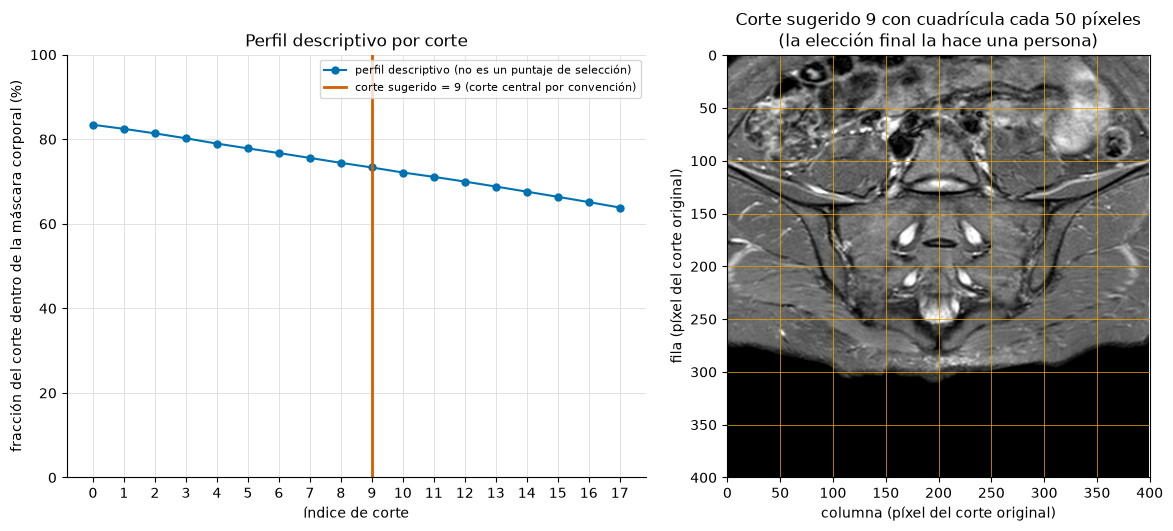

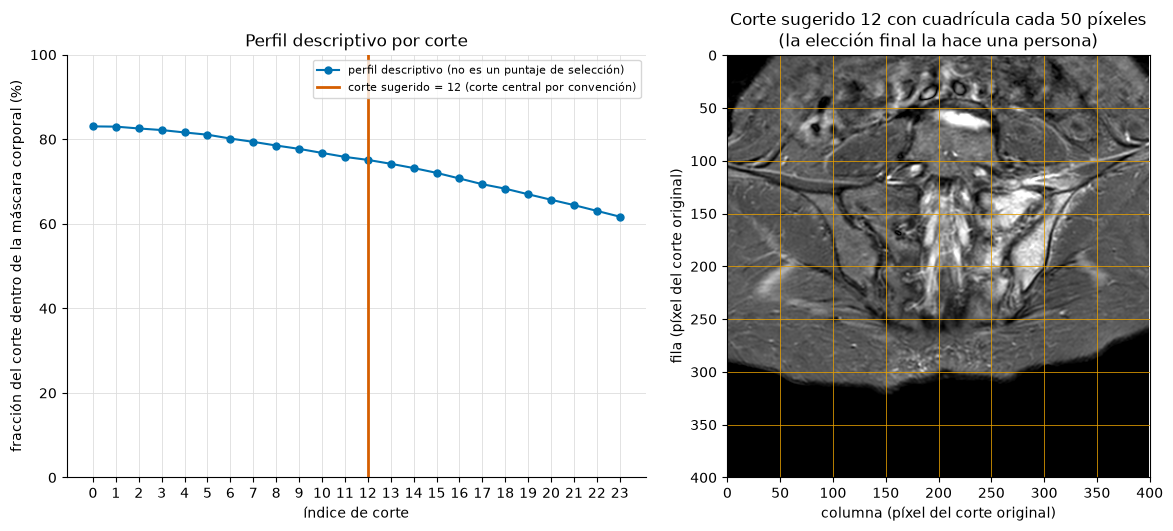

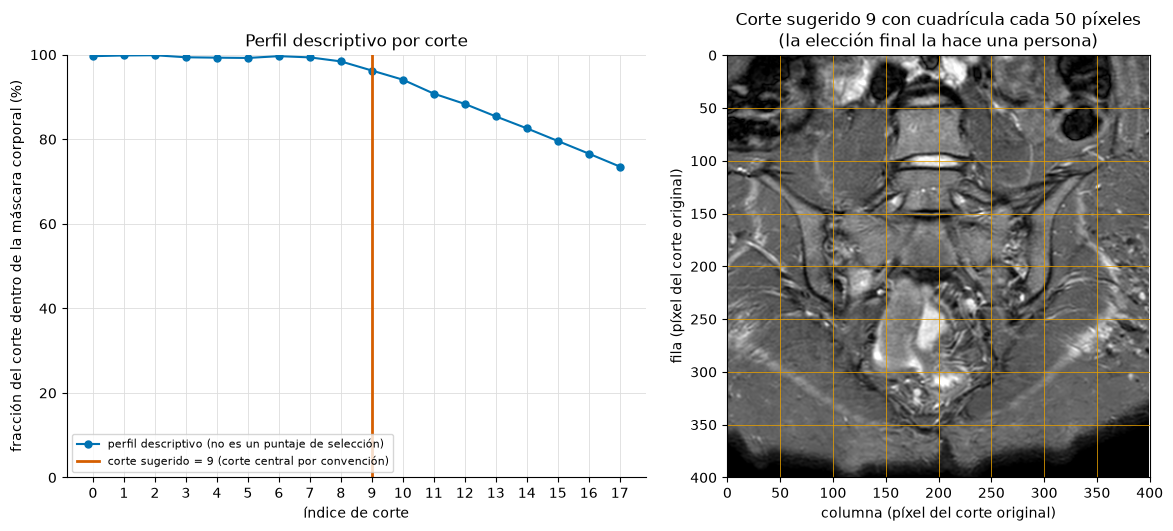

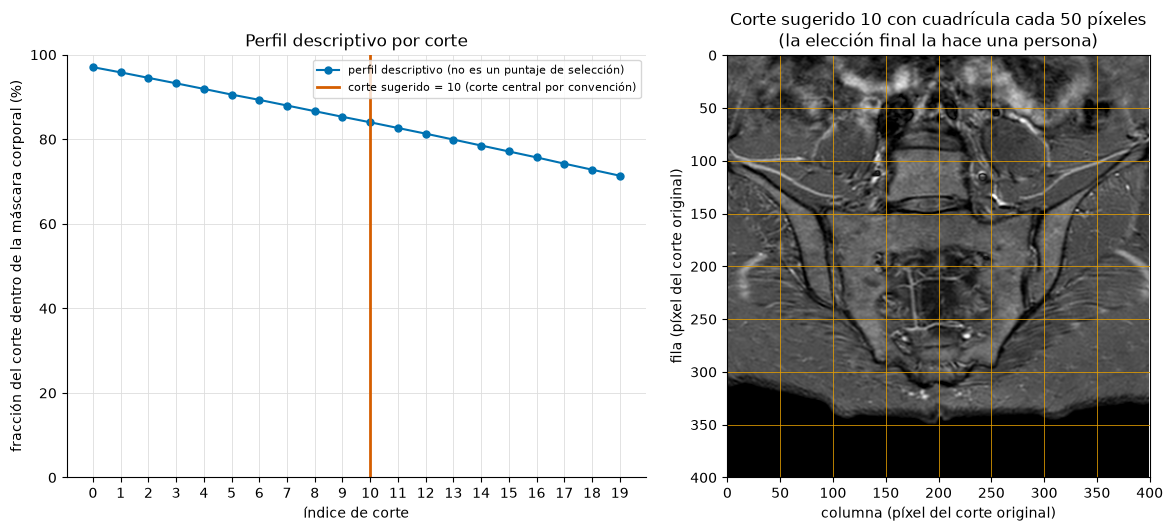

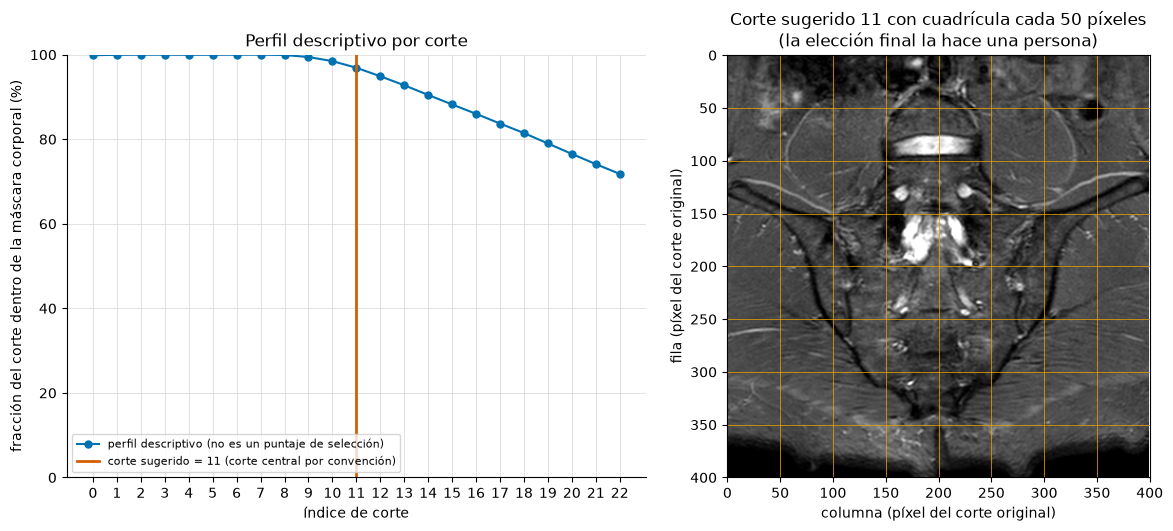

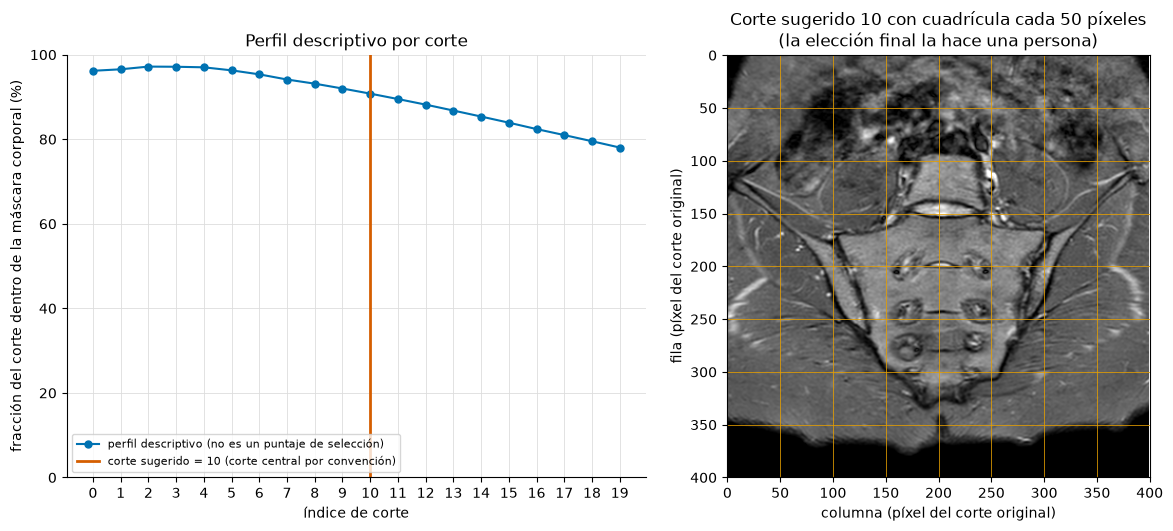

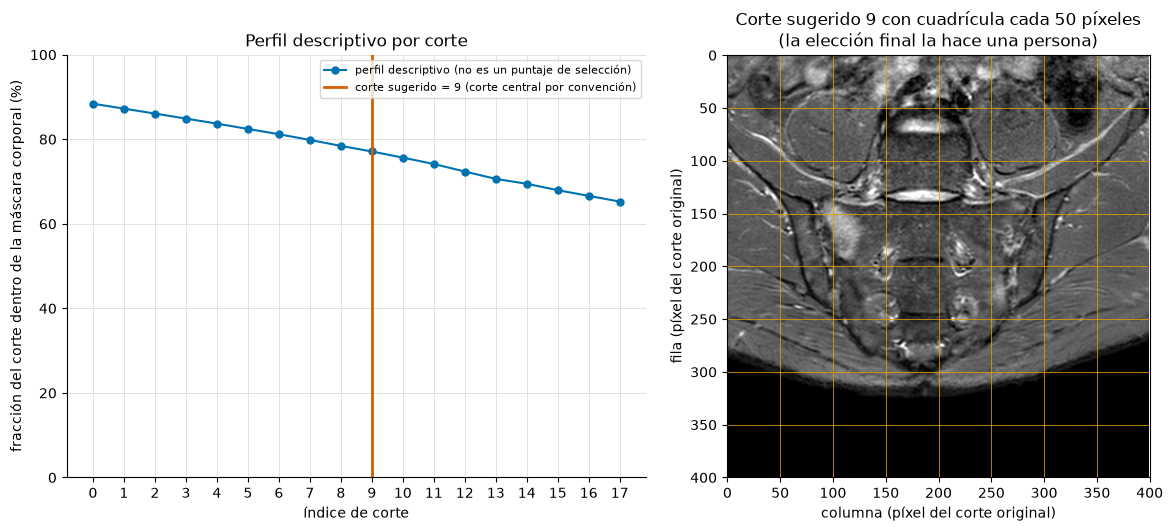

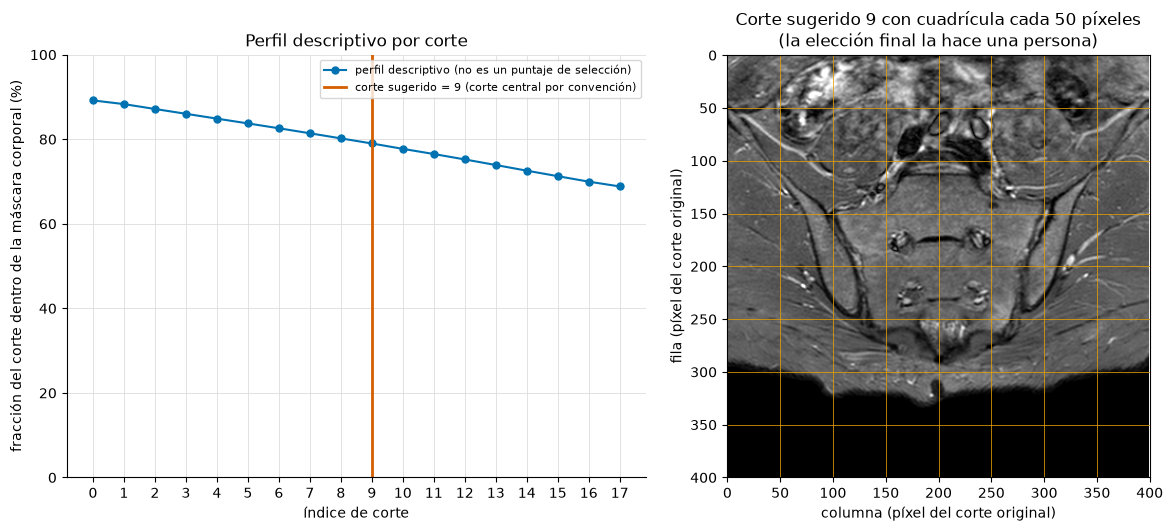

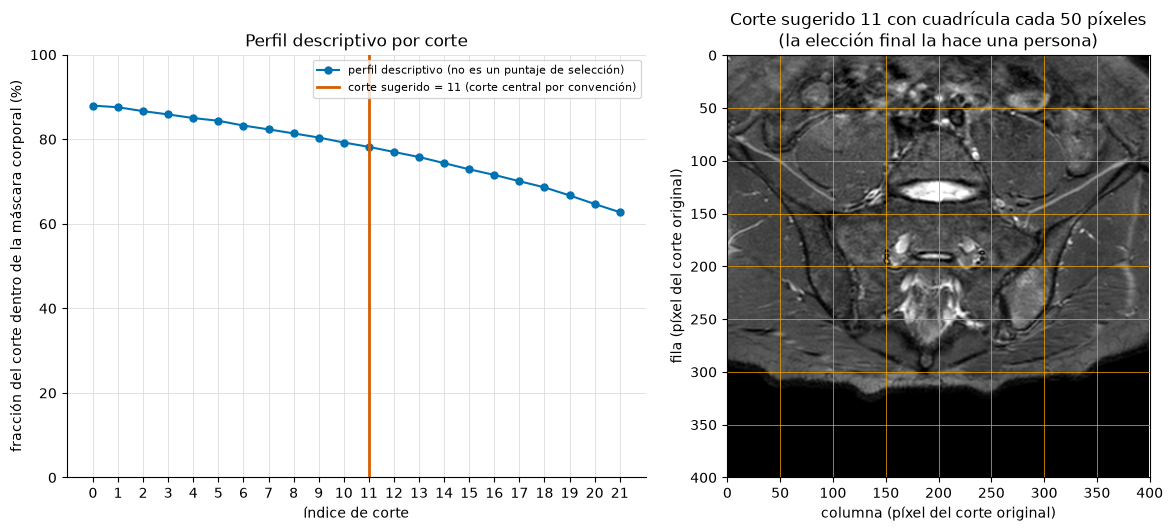

In [18]:
for k in vols_f:
    idx, perfil = key_slices[k]
    display(plot_key_slice(u8[k], idx, perfil))

## 11. Resumen y pasos siguientes

**Qué se produjo.**
- En `data/processed/`: 9 volúmenes `SIJ_<n>.npz` y 9 `SIJ_<n>.nii.gz` en `uint8` 0–255, con espaciado `(0.6, 0.6, 3.0)` mm, más `preprocessing_params.json` con los parámetros y los `sha256` de los archivos de origen. Nada de esto se sube al repositorio.
- El flujo fue: lectura y verificación de ejes, máscara del cuerpo (umbral bajo), N4 con 3 niveles (el CV bajó en los 9 volúmenes, de forma desigual), recorte por percentiles 0.5–99.5 dentro de la máscara, normalización por volumen y guardado.

**Lo que queda abierto.**
- **El criterio de recorte** se revisó solo en 2 volúmenes y 1 corte cada uno. Hay que repetir la revisión sobre cortes con edema antes de darlo por definitivo.
- **El corte clave** es una sugerencia; una persona debe confirmarlo y dibujar la caja.
- Las imágenes son de un solo centro, un solo escáner y solo STIR en coronal oblicuo (sección 2.2): los resultados valen en ese dominio.

**Pasos siguientes.**
1. **Inferencia de MedSAM2:** instalar el código del repositorio y los pesos de Hugging Face (`wanglab/MedSAM2`), decidir dónde correrla (Mac con CPU o Colab; sigue abierto) y dar la caja sobre el corte clave para obtener las máscaras.
2. **Normalización para la U-Net:** MedSAM2 necesita un recorte a 0–255, mientras que el estándar de nnU-Net en RM es el z-score por caso (Isensee et al., 2021). Pueden terminar siendo dos preparaciones distintas; la decisión queda fuera de este notebook (§8 del diseño).